# Analyzing connection between mass ratio and proxies for evolution

In [134]:
import matplotlib.pyplot as plt
import numpy as np
import numpy.ma as ma
from astropy.table import Table
from tqdm import tqdm
import matplotlib

In [154]:
matplotlib.rcParams['figure.dpi'] = 100
matplotlib.rcParams['savefig.dpi'] = 300
matplotlib.rcParams['axes.labelsize'] = 18
matplotlib.rcParams['xtick.labelsize'] = 16
matplotlib.rcParams['ytick.labelsize'] = 16

## load data

In [135]:
plot_dir= '/Users/nityaravi/Documents/Research/RotationCurves/data/manga/metallicity/'

In [136]:
master_table_fn = '/Users/nityaravi/Documents/Research/RotationCurves/data/manga/output_files/DR17/CURRENT_MASTER_TABLE/Elliptical_sphdisk_refitspirals_BPT_illustris_v11.fits'

master_table = Table.read(master_table_fn)
master_table[:5]

plate,ifudsgn,plateifu,mangaid,versdrp2,versdrp3,verscore,versutil,versprim,platetyp,srvymode,objra,objdec,ifuglon,ifuglat,ifura,ifudec,ebvgal,nexp,exptime,drp3qual,bluesn2,redsn2,harname,frlplug,cartid,designid,cenra,cendec,airmsmin,airmsmed,airmsmax,seemin,seemed,seemax,transmin,transmed,transmax,mjdmin,mjdmed,mjdmax,gfwhm,rfwhm,ifwhm,zfwhm,mngtarg1,mngtarg2,mngtarg3,catidnum,plttarg,manga_tileid,nsa_iauname,ifudesignsize,ifutargetsize,ifudesignwrongsize,z,zmin,zmax,szmin,szmax,ezmin,ezmax,probs,pweight,psweight,psrweight,sweight,srweight,eweight,esweight,esrweight,nsa_field,nsa_run,nsa_camcol,nsa_version,nsa_nsaid,nsa_nsaid_v1b,nsa_z,nsa_zdist,nsa_sersic_absmag,nsa_elpetro_absmag,nsa_elpetro_amivar,nsa_sersic_mass,nsa_elpetro_mass,nsa_elpetro_ba,nsa_elpetro_phi,nsa_extinction,nsa_elpetro_th50_r,nsa_petro_th50,nsa_petro_flux,nsa_petro_flux_ivar,nsa_elpetro_flux,nsa_elpetro_flux_ivar,nsa_sersic_ba,nsa_sersic_n,nsa_sersic_phi,nsa_sersic_th50,nsa_sersic_flux,nsa_sersic_flux_ivar,smoothness_score,nsa_elpetro_th90,v_sys,v_sys_err,ba,ba_err,x0,x0_err,y0,y0_err,phi,phi_err,v_max,v_max_err,r_turn,r_turn_err,chi2,alpha,alpha_err,Rmax,M,M_err,fit_flag,Sigma_disk,Sigma_disk_err,R_disk,R_disk_err,rho_bulge,rho_bulge_err,R_bulge,R_bulge_err,M90_disk,M90_disk_err,M_disk,M_disk_err,chi2_disk,WF50,WF50_err,DL_ttype,vis_tidal,b,b_err,M_R90,M_R90_err,fit_function,A_g,A_r,logH2,R90_kpc,v_3p5,v_3p5_err,NSA_plate,NSA_fiberID,NSA_MJD,logH2_CG,logH2_CG_err,logH2_M,Z,Z_err,M_Z,M_Z_err,grad_Z,grad_Z_err,Z_0,Z_0_err,SFR,sSFR,SFR_err,sSFR_err,Flux_OII_3726,Flux_OII_3726_Err,Flux_OII_3728,Flux_OII_3728_Err,Flux_OIII_4958,Flux_OIII_4958_Err,Flux_OIII_5006,Flux_OIII_5006_Err,Flux_NII_6547,Flux_NII_6547_Err,Flux_NII_6583,Flux_NII_6583_Err,Flux_Ha_6562,Flux_Ha_6562_Err,Flux_Hb_4861,Flux_Hb_4861_Err,CMD_class,rabsmag_NSA,param_H2,param_H2_err,Z_map,Z_err_map,M_Z_map,M_Z_err_map,logHI_R90,Mvir,Mvir_err,star_sigma,star_sigma_err,dipole_moment,Rgal,vflag_VF,nsa_elpetro_log_mass,rabsmag,param_H2_R90,logHe,sphd_rho_c,sphd_rho_c_err,sphd_R_scale,sphd_R_scale_err,sphd_Sigma_d,sphd_Sigma_d_err,sphd_R_d,sphd_R_d_err,sphd_M_star,sphd_M_star_err,sphd_chi2,mhq_R_scale,mhq_R_scale_err,mhq_M_star,mhq_M_star_err,mhq_gamma,mhq_gamma_err,mhq_chi2,hq_R_scale,hq_R_scale_err,hq_M_star,hq_M_star_err,hq_chi2,sph_rho_c,sph_rho_c_err,sph_R_scale,sph_R_scale_err,sph_M_star,sph_M_star_err,sph_chi2,sum_M_star,sum_M_star_err,BPT_class,spiral_mask,elliptical_mask,Age_LW_Re_fit,Age_MW_Re_fit,ZH_LW_Re_fit,ZH_MW_Re_fit,M90_disk_h,M90_disk_err_h,sphd_M_star_err_h,sphd_M_star_h,V_R90,V_R90_err,e_M_star_R90,e_M_star_R90_err,e_M_star_R90_h,e_M_star_R90_err_h,v_eff,v_eff_err,logHI,logHI_err,HI_catalog,logHI_h,logHI_err_h,N2Ha,O3Hb,nsa_u_r,illustris_match,illustris_dist,illustris_u_r,illustris_Mstar,illustris_Mstar_Sal,illustris_Vmax,illustris_flag,illustris_MR90,MH2_S14_vol,MHI_S14_vol,MHtot
int64,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,float64,float64,float64,float64,float64,float64,float64,int64,float64,int64,float64,float64,bytes53,int64,bytes32,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,float64,float64,float64,float64,int64,int64,int64,int64,bytes32,int64,bytes19,int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,bytes6,int64,int64,float64,float64,float64[7],float64[7],float64[7],float64,float64,float64,float64,float64[7],float64,float64,float64[7],float64[7],float64[7],float64[7],float64,float64,float64,float64,float64[7],float64[7],float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,

In [279]:
pipe3d_fn = '/Users/nityaravi/Documents/Research/RotationCurves/data/manga/SDSS17Pipe3D_v3_1_1.fits'
pipe3d = Table.read(pipe3d_fn)
pipe3d[:5]

name,plate,ifudsgn,plateifu,mangaid,objra,objdec,log_SFR_Ha,FoV,Re_kpc,e_log_Mass,e_log_SFR_Ha,log_Mass,log_SFR_ssp,log_NII_Ha_cen,e_log_NII_Ha_cen,log_OIII_Hb_cen,e_log_OIII_Hb_cen,log_SII_Ha_cen,e_log_SII_Ha_cen,log_OII_Hb_cen,e_log_OII_Hb_cen,EW_Ha_cen,e_EW_Ha_cen,ZH_LW_Re_fit,e_ZH_LW_Re_fit,alpha_ZH_LW_Re_fit,e_alpha_ZH_LW_Re_fit,ZH_MW_Re_fit,e_ZH_MW_Re_fit,alpha_ZH_MW_Re_fit,e_alpha_ZH_MW_Re_fit,Age_LW_Re_fit,e_Age_LW_Re_fit,alpha_Age_LW_Re_fit,e_alpha_Age_LW_Re_fit,Age_MW_Re_fit,e_Age_MW_Re_fit,alpha_Age_MW_Re_fit,e_alpha_Age_MW_Re_fit,Re_arc,DL,DA,PA,ellip,log_Mass_gas,vel_sigma_Re,e_vel_sigma_Re,log_SFR_SF,log_SFR_D_C,OH_O3N2_cen,e_OH_O3N2_cen,OH_N2_cen,e_OH_N2_cen,OH_ONS_cen,e_OH_ONS_cen,OH_R23_cen,e_OH_R23_cen,OH_pyqz_cen,e_OH_pyqz_cen,OH_t2_cen,e_OH_t2_cen,OH_M08_cen,e_OH_M08_cen,OH_T04_cen,e_OH_T04_cen,OH_dop_cen,e_OH_dop_cen,OH_O3N2_EPM09_cen,e_OH_O3N2_EPM09_cen,log_OI_Ha_cen,e_log_OI_Ha_cen,Ha_Hb_cen,e_Ha_Hb_cen,log_NII_Ha_Re,e_log_NII_Ha_Re,log_OIII_Hb_Re,e_log_OIII_Hb_Re,log_SII_Ha_Re,e_log_SII_Ha_Re,log_OII_Hb_Re,e_log_OII_Hb_Re,log_OI_Ha_Re,e_log_OI_Ha_Re,EW_Ha_Re,e_EW_Ha_Re,Ha_Hb_Re,e_Ha_Hb_Re,log_NII_Ha_ALL,e_log_NII_Ha_ALL,log_OIII_Hb_ALL,e_log_OIII_Hb_ALL,log_SII_Ha_ALL,e_log_SII_Ha_ALL,log_OII_Hb_ALL,e_log_OII_Hb_ALL,log_OI_Ha_ALL,e_log_OI_Ha_ALL,EW_Ha_ALL,e_EW_Ha_ALL,Ha_Hb_ALL,Sigma_Mass_cen,e_Sigma_Mass_cen,Sigma_Mass_Re,e_Sigma_Mass_Re,Sigma_Mass_ALL,e_Sigma_Mass_ALL,T30,ZH_T30,ZH_Re_T30,a_ZH_T30,T40,ZH_T40,ZH_Re_T40,a_ZH_T40,T50,ZH_T50,ZH_Re_T50,a_ZH_T50,T60,ZH_T60,ZH_Re_T60,a_ZH_T60,T70,ZH_T70,ZH_Re_T70,a_ZH_T70,T80,ZH_T80,ZH_Re_T80,a_ZH_T80,T90,ZH_T90,ZH_Re_T90,a_ZH_T90,T95,ZH_T95,ZH_Re_T95,a_ZH_T95,T99,ZH_T99,ZH_Re_T99,a_ZH_T99,log_Mass_gas_Av_gas_OH,log_Mass_gas_Av_ssp_OH,vel_ssp_2,e_vel_ssp_2,vel_Ha_2,e_vel_Ha_2,vel_ssp_1,e_vel_ssp_1,vel_Ha_1,e_vel_Ha_1,log_SFR_ssp_100Myr,log_SFR_ssp_10Myr,vel_disp_Ha_cen,vel_disp_ssp_cen,vel_disp_Ha_1Re,vel_disp_ssp_1Re,log_Mass_in_Re,ML_int,ML_avg,F_Ha_cen,e_F_Ha_cen,R50_kpc_V,e_R50_kpc_V,R50_kpc_Mass,e_R50_kpc_Mass,log_Mass_corr_in_R50_V,e_log_Mass_corr_in_R50_V,log_Mass_gas_Av_gas_log_log,Av_gas_Re,e_Av_gas_Re,Av_ssp_Re,e_Av_ssp_Re,Lambda_Re,e_Lambda_Re,nsa_redshift,nsa_mstar,nsa_inclination,flux_[OII]3726.03_Re_fit,e_flux_[OII]3726.03_Re_fit,flux_[OII]3726.03_alpha_fit,e_flux_[OII]3726.03_alpha_fit,flux_[OII]3728.82_Re_fit,e_flux_[OII]3728.82_Re_fit,flux_[OII]3728.82_alpha_fit,e_flux_[OII]3728.82_alpha_fit,flux_HI3734.37_Re_fit,e_flux_HI3734.37_Re_fit,flux_HI3734.37_alpha_fit,e_flux_HI3734.37_alpha_fit,flux_HI3797.9_Re_fit,e_flux_HI3797.9_Re_fit,flux_HI3797.9_alpha_fit,e_flux_HI3797.9_alpha_fit,flux_HeI3888.65_Re_fit,e_flux_HeI3888.65_Re_fit,flux_HeI3888.65_alpha_fit,e_flux_HeI3888.65_alpha_fit,flux_HI3889.05_Re_fit,e_flux_HI3889.05_Re_fit,flux_HI3889.05_alpha_fit,e_flux_HI3889.05_alpha_fit,flux_HeI3964.73_Re_fit,e_flux_HeI3964.73_Re_fit,flux_HeI3964.73_alpha_fit,e_flux_HeI3964.73_alpha_fit,flux_[NeIII]3967.46_Re_fit,e_flux_[NeIII]3967.46_Re_fit,flux_[NeIII]3967.46_alpha_fit,e_flux_[NeIII]3967.46_alpha_fit,flux_CaII3968.47_Re_fit,e_flux_CaII3968.47_Re_fit,flux_CaII3968.47_alpha_fit,e_flux_CaII3968.47_alpha_fit,flux_Hepsilon3970.07_Re_fit,e_flux_Hepsilon3970.07_Re_fit,flux_Hepsilon3970.07_alpha_fit,e_flux_Hepsilon3970.07_alpha_fit,flux_Hdelta4101.77_Re_fit,e_flux_Hdelta4101.77_Re_fit,flux_Hdelta4101.77_alpha_fit,e_flux_Hdelta4101.77_alpha_fit,flux_Hgamma4340.49_Re_fit,e_flux_Hgamma4340.49_Re_fit,flux_Hgamma4340.49_alpha_fit,e_flux_Hgamma4340.49_alpha_fit,flux_Hbeta4861.36_Re_fit,e_flux_Hbeta4861.36_Re_fit,flux_Hbeta4861.36_alpha_fit,e_flux_Hbeta4861.36_alpha_fit,flux_[OIII]4958.91_Re_fit,e_flux_[OIII]4958.91_Re_fit,flux_[OIII]4958.91_alpha_fit,e_flux_[OIII]4958.91_alpha_fit,flux_[OIII]5006.84_Re_fit,e_flux_[OIII]5006.84_Re_fit,flux_[OIII]5006.84_alpha_fit,e_flux_[OIII]5006.84_alpha_fit,flux_HeI5015.68_Re_fit,e_flux_HeI5015.68_Re_fit,flux_HeI5015.68_alpha_fit,e_flux_HeI5015.68_alpha_fit,flux_[NI]5197.9_Re_fit,e_flux_[NI]5197.9_Re_fit,flux_[NI]5197.9_alpha_fit

In [280]:
master_table_dict = {}
for i in range(len(master_table)):

    master_table_dict[master_table['mangaid'][i]] = i
    

In [281]:
for i in range(len(pipe3d)):

    idx  = master_table_dict[pipe3d['mangaid'][i]]

    master_table['Age_LW_Re_fit'][idx] = pipe3d['Age_LW_Re_fit'][i]
    master_table['Age_MW_Re_fit'][idx] = pipe3d['Age_MW_Re_fit'][i]
    master_table['ZH_LW_Re_fit'][idx] = pipe3d['ZH_LW_Re_fit'][i]
    master_table['ZH_MW_Re_fit'][idx] = pipe3d['ZH_MW_Re_fit'][i]



/Users/nityaravi/miniforge3/envs/RotationCurves/lib/python3.12/site-packages/astropy/table/column.py:1376: UserWarning: Warning: converting a masked element to nan.
  self.data[index] = value


## select spiral and elliptical sample

In [282]:
alpha_mask = master_table['alpha'] <= 99
vel_mask = np.logical_and(master_table['V_R90'] < 1000, master_table['V_R90'] > 10)
vel_err_mask = master_table['v_max_err']/master_table['v_max'] <= 2

In [283]:
spirals = master_table[np.logical_and(np.logical_and(alpha_mask, vel_mask), vel_err_mask)]
HI_spirals = spirals[spirals['logHI_R90'] > 0]
ellipticals = master_table[master_table['Mvir'] > 0]
metallicity_spirals = spirals[spirals['Z'] > 0]

In [284]:
HI_spirals['param_H2'] = np.zeros(len(HI_spirals))
HI_spirals['param_H2_h'] = np.zeros(len(HI_spirals))
HI_spirals['param_He_h'] = np.zeros(len(HI_spirals))
HI_spirals['param_He90_h'] = np.zeros(len(HI_spirals))
HI_spirals['Mbar'] = np.zeros(len(HI_spirals))


for i in range(len(HI_spirals)):
    
    if HI_spirals['CMD_class'][i] == 1:
        HI_spirals['param_H2'][i] = -0.4*HI_spirals['rabsmag'][i] +1.12
    elif HI_spirals['CMD_class'][i] == 2 or HI_spirals['CMD_class'][i] == 3:
        HI_spirals['param_H2'][i] = -0.27*HI_spirals['rabsmag'][i] + 3.62

    HI_spirals['param_H2_h'][i] = HI_spirals['param_H2'][i] + np.log10(0.7)
    HI_spirals['param_He_h'][i] = np.log10(0.7) -np.log10(3) + np.log10(10**HI_spirals['logHI'][i] + 10**HI_spirals['param_H2'][i])
    HI_spirals['param_He90_h'][i] = np.log10(0.7) -np.log10(3) + np.log10(10**HI_spirals['logHI_R90'][i] + 10**HI_spirals['param_H2'][i])



for i in range(len(HI_spirals)):
    HI_spirals['Mbar'][i] = np.log10(10**(HI_spirals['M90_disk'][i] + np.log10(0.73)) + 10**(HI_spirals['logHI_R90'][i]+np.log10(0.7)) + 10**HI_spirals['param_H2_h'][i] + 10**HI_spirals['param_He90_h'][i])

In [285]:
HI_spirals['Mtot_Mvis'] = 10**(HI_spirals['M_R90']-HI_spirals['Mbar'])
HI_spirals['Mtot_Mstar'] = 10**(HI_spirals['M_R90']-(HI_spirals['M90_disk']+np.log10(0.73)))

spirals['Mtot_Mstar'] = 10**(spirals['M_R90']-(spirals['M90_disk']+np.log10(0.73)))

ellipticals['Mtot_Mstar'] = 10**(ellipticals['Mvir'] - ellipticals['e_M_star_R90_h'])
ellipticals['Mtot_Mvis'] = 10**(ellipticals['Mvir'] - ellipticals['e_M_star_R90_h'])

/Users/nityaravi/miniforge3/envs/RotationCurves/lib/python3.12/site-packages/numpy/ma/core.py:6980: RuntimeWarning: overflow encountered in power
  result = np.where(m, fa, umath.power(fa, fb)).view(basetype)


In [286]:
blue_spirals = spirals[spirals['CMD_class'] == 1]
green_spirals = spirals[spirals['CMD_class'] == 2]
red_spirals = spirals[spirals['CMD_class'] == 3]


In [287]:
HI_blue = HI_spirals[HI_spirals['CMD_class'] == 1]
HI_green = HI_spirals[HI_spirals['CMD_class'] == 2]
HI_red = HI_spirals[HI_spirals['CMD_class'] == 3]

In [288]:
metallicity_blue = blue_spirals[blue_spirals['Z'] > 0]
metallicity_green = green_spirals[green_spirals['Z'] > 0]
metallicity_red = red_spirals[red_spirals['Z'] > 0]

(array([361., 717., 458., 282., 234., 199., 133.,  59.,  20.,   4.]),
 array([-23.028397 , -22.3425073, -21.6566176, -20.9707279, -20.2848382,
        -19.5989485, -18.9130588, -18.2271691, -17.5412794, -16.8553897,
        -16.1695   ]),
 <BarContainer object of 10 artists>)

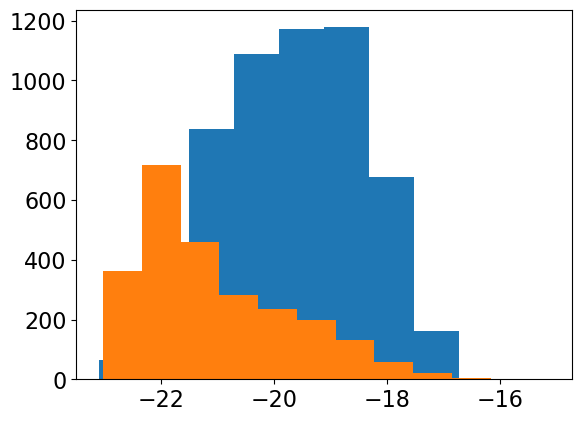

In [315]:
plt.hist(spirals['rabsmag'])
plt.hist(ellipticals['rabsmag'])

## tng matching

## Single parameter plots

### MaNGA gas-phase metallicity vs. magnitude

In [316]:
mr_bins = np.linspace(-17, -22.5,7)
b_ind = np.digitize(metallicity_blue['rabsmag'], mr_bins, right=True)
g_ind = np.digitize(metallicity_green['rabsmag'], mr_bins, right=True)
r_ind = np.digitize(metallicity_red['rabsmag'], mr_bins, right=True)

In [317]:
b_med = []
b_scat = []
b_pct = []


g_med = []
g_scat = []
g_pct = []

r_med = []
r_scat = []
r_pct = []

for i in range(1,7):

    b_med.append(np.median(metallicity_blue[b_ind == i]['Z']))
    b_scat.append(np.std(metallicity_blue[b_ind == i]['Z']))
    b_pct.append(np.percentile(metallicity_blue[b_ind == i]['Z'], [16,84]))

    g_med.append(np.median(metallicity_green[g_ind == i]['Z']))
    g_scat.append(np.std(metallicity_green[g_ind == i]['Z']))
    g_pct.append(np.percentile(metallicity_green[g_ind == i]['Z'], [16,84]))

    r_med.append(np.median(metallicity_red[r_ind == i]['Z']))
    r_scat.append(np.std(metallicity_red[r_ind == i]['Z']))
    r_pct.append(np.percentile(metallicity_red[r_ind == i]['Z'], [16,84]))


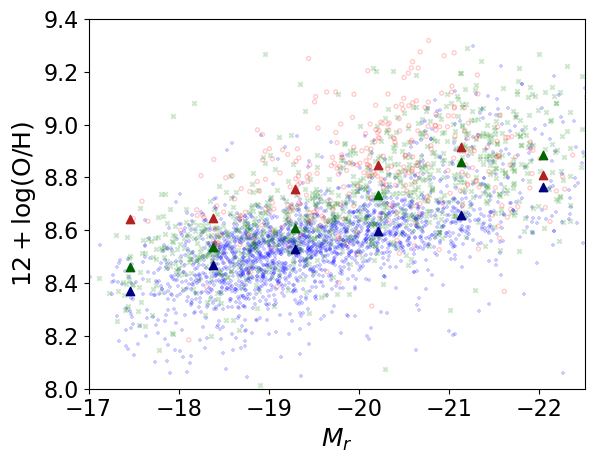

In [320]:
plt.scatter(metallicity_blue['rabsmag'], metallicity_blue['Z'], marker='+', color='b', s=10, alpha=0.2)
plt.scatter(metallicity_green['rabsmag'], metallicity_green['Z'], marker='x', color='g', s=10, alpha=0.2)
plt.scatter(metallicity_red['rabsmag'], metallicity_red['Z'], marker='o', edgecolor='r', facecolor='none',s=8, alpha=0.2)

# plt.errorbar((mr_bins[1:] + mr_bins[:-1])/2, b_med, yerr=np.abs(np.transpose(b_pct) - b_med), linestyle='none', marker='^', color='navy')
# plt.errorbar((mr_bins[1:] + mr_bins[:-1])/2, g_med, yerr=np.abs(np.transpose(g_pct) - g_med), linestyle='none', marker='^', color='darkgreen')
# plt.errorbar((mr_bins[1:] + mr_bins[:-1])/2, r_med, yerr=np.abs(np.transpose(r_pct) - r_med), linestyle='none', marker='^', color='firebrick')


plt.scatter((mr_bins[1:] + mr_bins[:-1])/2, b_med,  marker='^', color='navy')
plt.scatter((mr_bins[1:] + mr_bins[:-1])/2, g_med, marker='^', color='darkgreen')
plt.scatter((mr_bins[1:] + mr_bins[:-1])/2, r_med, marker='^', color='firebrick')

plt.xlim(-17,-22.5)
plt.ylim(8,9.4)
plt.xlabel(r'$M_r$')
plt.ylabel(r'$12 + \log(\rm O/H)$')
plt.savefig(plot_dir + 'Mr_12logOH_manga_scatter.png', bbox_inches='tight')

### mass ratios vs metallcity

In [321]:
z_bins = np.linspace(8,9.4,6)
b_ind = np.digitize(metallicity_blue['Z'], z_bins, right=True)
g_ind = np.digitize(metallicity_green['Z'], z_bins, right=True)
r_ind = np.digitize(metallicity_red['Z'], z_bins, right=True)

In [322]:
b_med = []
b_scat = []
b_pct = []


g_med = []
g_scat = []
g_pct = []

r_med = []
r_scat = []
r_pct = []

for i in range(1,6):

    b_med.append(np.median(metallicity_blue[b_ind == i]['Mtot_Mstar']))
    b_scat.append(np.std(metallicity_blue[b_ind == i]['Mtot_Mstar']))
    b_pct.append(np.percentile(metallicity_blue[b_ind == i]['Mtot_Mstar'], [16,84]))

    g_med.append(np.median(metallicity_green[g_ind == i]['Mtot_Mstar']))
    g_scat.append(np.std(metallicity_green[g_ind == i]['Mtot_Mstar']))
    g_pct.append(np.percentile(metallicity_green[g_ind == i]['Mtot_Mstar'], [16,84]))

    r_med.append(np.median(metallicity_red[r_ind == i]['Mtot_Mstar']))
    r_scat.append(np.std(metallicity_red[r_ind == i]['Mtot_Mstar']))
    r_pct.append(np.percentile(metallicity_red[r_ind == i]['Mtot_Mstar'], [16,84]))


/Users/nityaravi/miniforge3/envs/RotationCurves/lib/python3.12/site-packages/numpy/lib/function_base.py:4824: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  arr.partition(


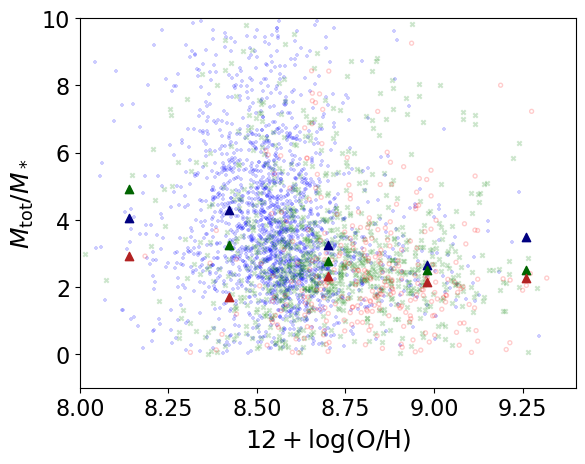

In [324]:
plt.scatter(metallicity_blue['Z'], metallicity_blue['Mtot_Mstar'], marker='+', color='b', s=10, alpha=0.2)
plt.scatter(metallicity_green['Z'], metallicity_green['Mtot_Mstar'], marker='x', color='g', s=10, alpha=0.2)
plt.scatter(metallicity_red['Z'], metallicity_red['Mtot_Mstar'], marker='o', edgecolor='r', facecolor='none',s=8, alpha=0.2)

# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, b_med, yerr=np.abs(np.transpose(b_pct) - b_med), linestyle='none', marker='^', color='navy')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, g_med, yerr=np.abs(np.transpose(g_pct) - g_med), linestyle='none', marker='^', color='darkgreen')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, r_med, yerr=np.abs(np.transpose(r_pct) - r_med), linestyle='none', marker='^', color='firebrick')

plt.scatter((z_bins[1:] + z_bins[:-1])/2, b_med, marker='^', color='navy')
plt.scatter((z_bins[1:] + z_bins[:-1])/2, g_med,  marker='^', color='darkgreen')
plt.scatter((z_bins[1:] + z_bins[:-1])/2, r_med,  marker='^', color='firebrick')


plt.ylim(-1,10)
plt.xlim(8,9.4)
plt.ylabel(r'$M_{\rm tot}/M_*$')
plt.xlabel(r'$12 + \log(\rm O/H)$')
plt.savefig(plot_dir + '12logOH_MtotMstar_manga_scatter.png', bbox_inches='tight')

In [325]:
HI_metallicity_blue = HI_spirals[np.logical_and(HI_spirals['Z'] > 0, HI_spirals['CMD_class'] == 1)]
HI_metallicity_green = HI_spirals[np.logical_and(HI_spirals['Z'] > 0, HI_spirals['CMD_class'] == 2)]
HI_metallicity_red = HI_spirals[np.logical_and(HI_spirals['Z'] > 0, HI_spirals['CMD_class'] == 3)]

b_ind = np.digitize(HI_metallicity_blue['Z'], z_bins, right=True)
g_ind = np.digitize(HI_metallicity_green['Z'], z_bins, right=True)
r_ind = np.digitize(HI_metallicity_red['Z'], z_bins, right=True)

In [326]:
b_med = []
b_scat = []
b_pct = []


g_med = []
g_scat = []
g_pct = []

r_med = []
r_scat = []
r_pct = []

for i in range(1,6):

    b_med.append(np.median(HI_metallicity_blue[b_ind == i]['Mtot_Mvis']))
    b_scat.append(np.std(HI_metallicity_blue[b_ind == i]['Mtot_Mvis']))
    # b_pct.append(np.percentile(HI_metallicity_blue[b_ind == i]['Mtot_Mvis'], [16,84]))

    g_med.append(np.median(HI_metallicity_green[g_ind == i]['Mtot_Mvis']))
    g_scat.append(np.std(HI_metallicity_green[g_ind == i]['Mtot_Mvis']))
    # g_pct.append(np.percentile(HI_metallicity_green[g_ind == i]['Mtot_Mvis'], [16,84]))

    r_med.append(np.median(HI_metallicity_red[r_ind == i]['Mtot_Mvis']))
    r_scat.append(np.std(HI_metallicity_red[r_ind == i]['Mtot_Mvis']))
    # r_pct.append(np.percentile(HI_metallicity_red[r_ind == i]['Mtot_Mvis'], [16,84]))


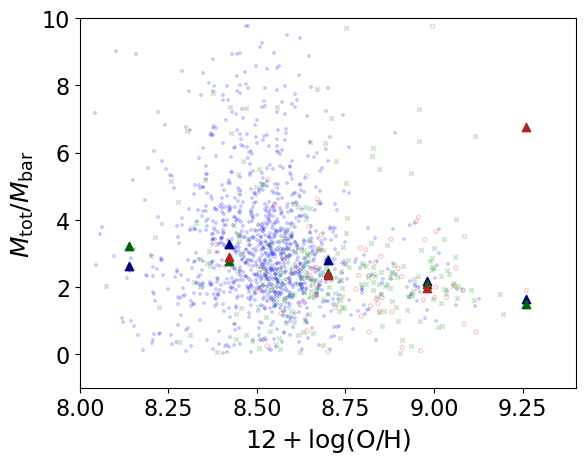

In [327]:
plt.scatter(HI_metallicity_blue['Z'], HI_metallicity_blue['Mtot_Mvis'], marker='+', color='b', s=10, alpha=0.2)
plt.scatter(HI_metallicity_green['Z'], HI_metallicity_green['Mtot_Mvis'], marker='x', color='g', s=10, alpha=0.2)
plt.scatter(HI_metallicity_red['Z'], HI_metallicity_red['Mtot_Mvis'], marker='o', edgecolor='r', facecolor='none',s=8, alpha=0.2)

# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, b_med, yerr=np.abs(np.transpose(b_pct) - b_med), linestyle='none', marker='^', color='navy')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, g_med, yerr=np.abs(np.transpose(g_pct) - g_med), linestyle='none', marker='^', color='darkgreen')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, r_med, yerr=np.abs(np.transpose(r_pct) - r_med), linestyle='none', marker='^', color='firebrick')

plt.scatter((z_bins[1:] + z_bins[:-1])/2, b_med,  marker='^', color='navy')
plt.scatter((z_bins[1:] + z_bins[:-1])/2, g_med,  marker='^', color='darkgreen')
plt.scatter((z_bins[1:] + z_bins[:-1])/2, r_med,  marker='^', color='firebrick')

plt.ylim(-1,10)
plt.xlim(8,9.4)
plt.ylabel(r'$M_{\rm tot}/M_{\rm bar}$')
plt.xlabel(r'$12 + \log(\rm O/H)$')
plt.savefig(plot_dir + '12logOH_MtotMvis_manga_scatter.png', bbox_inches='tight')

#### in magnitude bins

In [ ]:
mag_bins = np.linspace(

### mass ratio vs R90

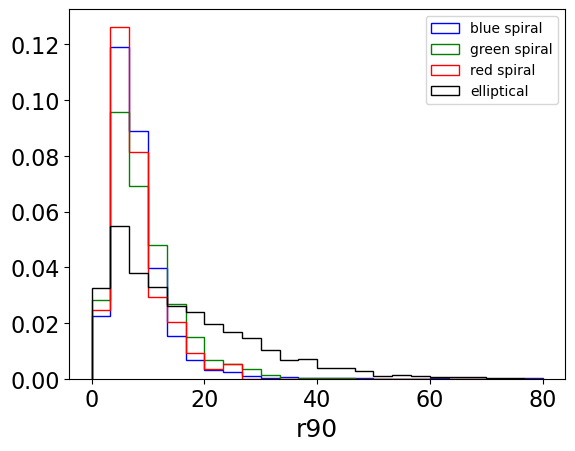

In [402]:
plt.hist(blue_spirals['R90_kpc'], bins=np.linspace(0,80,25), density=True, alpha=1, histtype='step', edgecolor='b', label='blue spiral')
plt.hist(green_spirals['R90_kpc'], bins=np.linspace(0,80,25), density=True, color='g', histtype='step', alpha=1, label='green spiral')
plt.hist(red_spirals['R90_kpc'], bins=np.linspace(0,80,25), density=True, color='r', histtype='step',alpha=1, label='red spiral')

plt.hist(ellipticals['R90_kpc'], bins=np.linspace(0,80,25), alpha=1, density=True, histtype='step',color='k', label='elliptical')
plt.xlabel('r90')

plt.legend()

In [371]:
R90_bins = np.linspace(0,40,8)
b_ind = np.digitize(blue_spirals['R90_kpc'], R90_bins, right=True)
g_ind = np.digitize(green_spirals['R90_kpc'], R90_bins, right=True)
r_ind = np.digitize(red_spirals['R90_kpc'], R90_bins, right=True)
e_ind = np.digitize(ellipticals['R90_kpc'], R90_bins, right=True)

In [373]:
b_med = []
b_scat = []

g_med = []
g_scat = []

r_med = []
r_scat = []

e_med = []
e_scat = []

for i in range(1,8):

    b_med.append(np.median(blue_spirals[b_ind == i]['Mtot_Mstar']))
    b_scat.append(np.std(blue_spirals[b_ind == i]['Mtot_Mstar']))
    # b_pct.append(np.percentile(HI_metallicity_blue[b_ind == i]['Mtot_Mvis'], [16,84]))

    g_med.append(np.median(green_spirals[g_ind == i]['Mtot_Mstar']))
    g_scat.append(np.std(green_spirals[g_ind == i]['Mtot_Mstar']))
    # g_pct.append(np.percentile(HI_metallicity_green[g_ind == i]['Mtot_Mvis'], [16,84]))

    r_med.append(np.median(red_spirals[r_ind == i]['Mtot_Mstar']))
    r_scat.append(np.std(red_spirals[r_ind == i]['Mtot_Mstar']))
    # r_pct.append(np.percentile(HI_metallicity_red[r_ind == i]['Mtot_Mvis'], [16,84]))

    e_med.append(np.median(ellipticals[e_ind == i]['Mtot_Mstar']))
    e_scat.append(np.std(ellipticals[e_ind == i]['Mtot_Mstar']))

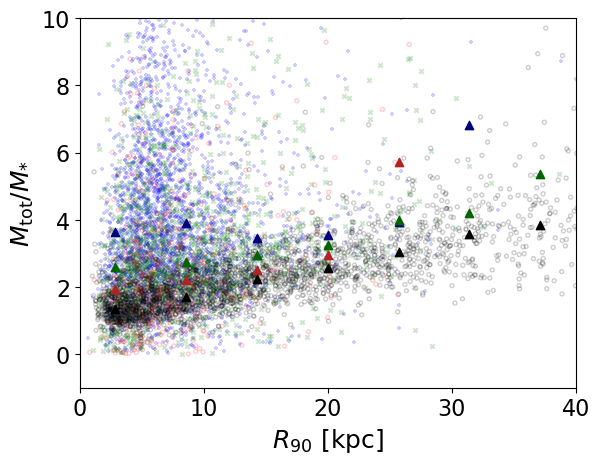

In [374]:
plt.scatter(blue_spirals['R90_kpc'], blue_spirals['Mtot_Mstar'], marker='+', color='b', s=10, alpha=0.2)
plt.scatter(green_spirals['R90_kpc'], green_spirals['Mtot_Mstar'], marker='x', color='g', s=10, alpha=0.2)
plt.scatter(red_spirals['R90_kpc'], red_spirals['Mtot_Mstar'], marker='o', edgecolor='r', facecolor='none',s=8, alpha=0.2)
plt.scatter(ellipticals['R90_kpc'], ellipticals['Mtot_Mstar'], marker='o', edgecolor='k', facecolor='none',s=8, alpha=0.2)


# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, b_med, yerr=np.abs(np.transpose(b_pct) - b_med), linestyle='none', marker='^', color='navy')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, g_med, yerr=np.abs(np.transpose(g_pct) - g_med), linestyle='none', marker='^', color='darkgreen')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, r_med, yerr=np.abs(np.transpose(r_pct) - r_med), linestyle='none', marker='^', color='firebrick')

plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, b_med,  marker='^', color='navy')
plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, g_med,  marker='^', color='darkgreen')
plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, r_med,  marker='^', color='firebrick')
plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, e_med,  marker='^', color='k')


plt.ylim(-1,10)
plt.xlim(0,40)
plt.ylabel(r'$M_{\rm tot}/M_{*}$')
plt.xlabel(r'$R_{90}$ [kpc]')
plt.savefig(plot_dir + 'R90_MtotMstar_manga_scatter.png', bbox_inches='tight')

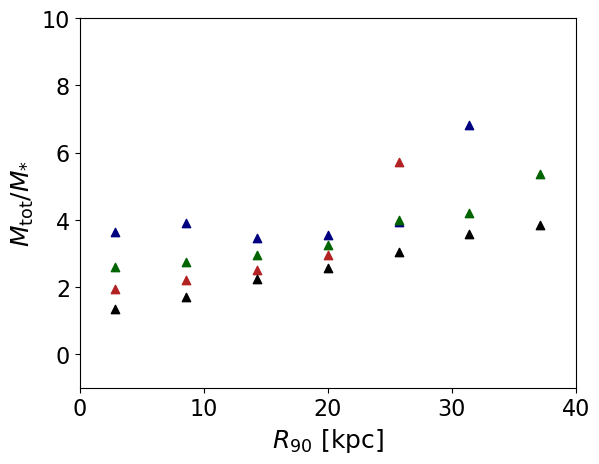

In [375]:
plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, b_med,  marker='^', color='navy')
plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, g_med,  marker='^', color='darkgreen')
plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, r_med,  marker='^', color='firebrick')
plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, e_med,  marker='^', color='k')


plt.ylim(-1,10)
plt.xlim(0,40)
plt.ylabel(r'$M_{\rm tot}/M_{*}$')
plt.xlabel(r'$R_{90}$ [kpc]')
plt.savefig(plot_dir + 'R90_MtotMstar_manga_scatter_median.png', bbox_inches='tight')

In [376]:
b_ind = np.digitize(HI_blue['R90_kpc'], R90_bins, right=True)
g_ind = np.digitize(HI_green['R90_kpc'], R90_bins, right=True)
r_ind = np.digitize(HI_red['R90_kpc'], R90_bins, right=True)
e_ind = np.digitize(ellipticals['R90_kpc'], R90_bins, right=True)

In [377]:
b_med = []
b_scat = []

g_med = []
g_scat = []

r_med = []
r_scat = []

e_med = []
e_scat = []

for i in range(1,8):

    b_med.append(np.median(HI_blue[b_ind == i]['Mtot_Mvis']))
    b_scat.append(np.std(HI_blue[b_ind == i]['Mtot_Mvis']))
    # b_pct.append(np.percentile(HI_metallicity_blue[b_ind == i]['Mtot_Mvis'], [16,84]))

    g_med.append(np.median(HI_green[g_ind == i]['Mtot_Mvis']))
    g_scat.append(np.std(HI_green[g_ind == i]['Mtot_Mvis']))
    # g_pct.append(np.percentile(HI_metallicity_green[g_ind == i]['Mtot_Mvis'], [16,84]))

    r_med.append(np.median(HI_red[r_ind == i]['Mtot_Mvis']))
    r_scat.append(np.std(HI_red[r_ind == i]['Mtot_Mvis']))
    # r_pct.append(np.percentile(HI_metallicity_red[r_ind == i]['Mtot_Mvis'], [16,84]))

    e_med.append(np.median(ellipticals[e_ind == i]['Mtot_Mvis']))
    e_scat.append(np.std(ellipticals[e_ind == i]['Mtot_Mvis']))

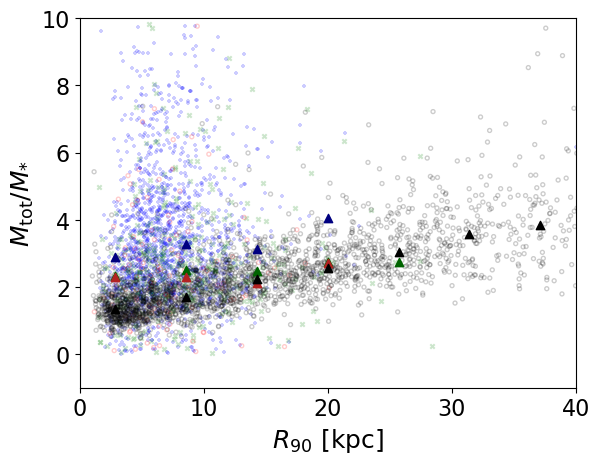

In [378]:
plt.scatter(HI_blue['R90_kpc'], HI_blue['Mtot_Mvis'], marker='+', color='b', s=10, alpha=0.2)
plt.scatter(HI_green['R90_kpc'], HI_green['Mtot_Mvis'], marker='x', color='g', s=10, alpha=0.2)
plt.scatter(HI_red['R90_kpc'], HI_red['Mtot_Mvis'], marker='o', edgecolor='r', facecolor='none',s=8, alpha=0.2)
plt.scatter(ellipticals['R90_kpc'], ellipticals['Mtot_Mvis'], marker='o', edgecolor='k', facecolor='none',s=8, alpha=0.2)


# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, b_med, yerr=np.abs(np.transpose(b_pct) - b_med), linestyle='none', marker='^', color='navy')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, g_med, yerr=np.abs(np.transpose(g_pct) - g_med), linestyle='none', marker='^', color='darkgreen')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, r_med, yerr=np.abs(np.transpose(r_pct) - r_med), linestyle='none', marker='^', color='firebrick')

plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, b_med,  marker='^', color='navy')
plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, g_med,  marker='^', color='darkgreen')
plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, r_med,  marker='^', color='firebrick')
plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, e_med,  marker='^', color='k')


plt.ylim(-1,10)
plt.xlim(0,40)
plt.ylabel(r'$M_{\rm tot}/M_{*}$')
plt.xlabel(r'$R_{90}$ [kpc]')
plt.savefig(plot_dir + 'R90_MtotMvis_manga_scatter.png', bbox_inches='tight')

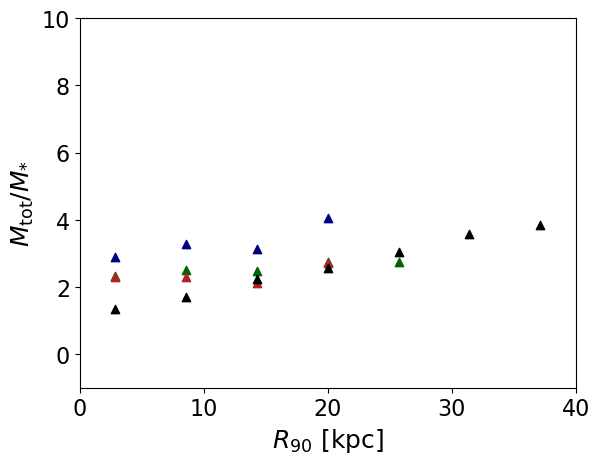

In [379]:
# plt.scatter(HI_blue['R90_kpc'], HI_blue['Mtot_Mvis'], marker='+', color='b', s=10, alpha=0.3)
# plt.scatter(HI_green['R90_kpc'], HI_green['Mtot_Mvis'], marker='x', color='g', s=10, alpha=0.3)
# plt.scatter(HI_red['R90_kpc'], HI_red['Mtot_Mvis'], marker='o', edgecolor='r', facecolor='none',s=8, alpha=0.3)
# plt.scatter(ellipticals['R90_kpc'], ellipticals['Mtot_Mvis'], marker='o', edgecolor='k', facecolor='none',s=8, alpha=0.3)


# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, b_med, yerr=np.abs(np.transpose(b_pct) - b_med), linestyle='none', marker='^', color='navy')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, g_med, yerr=np.abs(np.transpose(g_pct) - g_med), linestyle='none', marker='^', color='darkgreen')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, r_med, yerr=np.abs(np.transpose(r_pct) - r_med), linestyle='none', marker='^', color='firebrick')

plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, b_med,  marker='^', color='navy')
plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, g_med,  marker='^', color='darkgreen')
plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, r_med,  marker='^', color='firebrick')
plt.scatter((R90_bins[1:] + R90_bins[:-1])/2, e_med,  marker='^', color='k')


plt.ylim(-1,10)
plt.xlim(0,40)
plt.ylabel(r'$M_{\rm tot}/M_{*}$')
plt.xlabel(r'$R_{90}$ [kpc]')
plt.savefig(plot_dir + 'R90_MtotMvis_manga_scatter_media.png', bbox_inches='tight')

### MW stellar metallicity

In [336]:
MW_Z_bins = np.linspace(-1.5,0.3,8)
b_ind = np.digitize(blue_spirals['ZH_MW_Re_fit'], MW_Z_bins, right=True)
g_ind = np.digitize(green_spirals['ZH_MW_Re_fit'], MW_Z_bins, right=True)
r_ind = np.digitize(red_spirals['ZH_MW_Re_fit'], MW_Z_bins, right=True)
e_ind = np.digitize(ellipticals['ZH_MW_Re_fit'], MW_Z_bins, right=True)

In [337]:
b_med = []
b_scat = []

g_med = []
g_scat = []

r_med = []
r_scat = []

e_med = []
e_scat = []

for i in range(1,8):

    b_med.append(np.median(blue_spirals[b_ind == i]['Mtot_Mstar']))
    b_scat.append(np.std(blue_spirals[b_ind == i]['Mtot_Mstar']))
    # b_pct.append(np.percentile(HI_metallicity_blue[b_ind == i]['Mtot_Mvis'], [16,84]))

    g_med.append(np.median(green_spirals[g_ind == i]['Mtot_Mstar']))
    g_scat.append(np.std(green_spirals[g_ind == i]['Mtot_Mstar']))
    # g_pct.append(np.percentile(HI_metallicity_green[g_ind == i]['Mtot_Mvis'], [16,84]))

    r_med.append(np.median(red_spirals[r_ind == i]['Mtot_Mstar']))
    r_scat.append(np.std(red_spirals[r_ind == i]['Mtot_Mstar']))
    # r_pct.append(np.percentile(HI_metallicity_red[r_ind == i]['Mtot_Mvis'], [16,84]))

    e_med.append(np.median(ellipticals[e_ind == i]['Mtot_Mstar']))
    e_scat.append(np.std(ellipticals[e_ind == i]['Mtot_Mstar']))

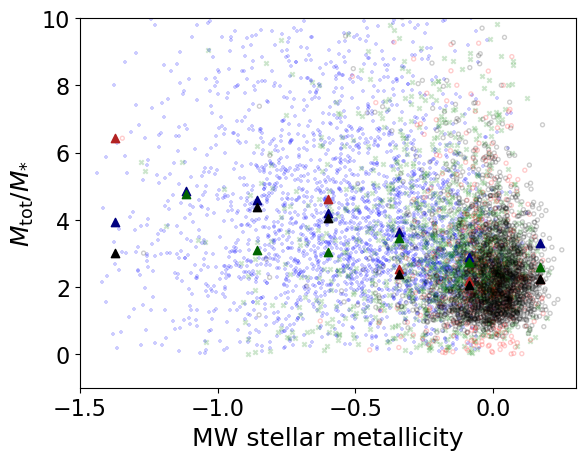

In [338]:
plt.scatter(blue_spirals['ZH_MW_Re_fit'], blue_spirals['Mtot_Mstar'], marker='+', color='b', s=10, alpha=0.2)
plt.scatter(green_spirals['ZH_MW_Re_fit'], green_spirals['Mtot_Mstar'], marker='x', color='g', s=10, alpha=0.2)
plt.scatter(red_spirals['ZH_MW_Re_fit'], red_spirals['Mtot_Mstar'], marker='o', edgecolor='r', facecolor='none',s=8, alpha=0.2)
plt.scatter(ellipticals['ZH_MW_Re_fit'], ellipticals['Mtot_Mstar'], marker='o', edgecolor='k', facecolor='none',s=8, alpha=0.2)


# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, b_med, yerr=np.abs(np.transpose(b_pct) - b_med), linestyle='none', marker='^', color='navy')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, g_med, yerr=np.abs(np.transpose(g_pct) - g_med), linestyle='none', marker='^', color='darkgreen')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, r_med, yerr=np.abs(np.transpose(r_pct) - r_med), linestyle='none', marker='^', color='firebrick')

plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, b_med,  marker='^', color='navy')
plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, g_med,  marker='^', color='darkgreen')
plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, r_med,  marker='^', color='firebrick')
plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, e_med,  marker='^', color='k')


plt.ylim(-1,10)
plt.xlim(-1.5,0.3)
plt.ylabel(r'$M_{\rm tot}/M_{*}$')
plt.xlabel(r'MW stellar metallicity')
plt.savefig(plot_dir + 'MWZ_MtotMstar_manga_scatter.png', bbox_inches='tight')

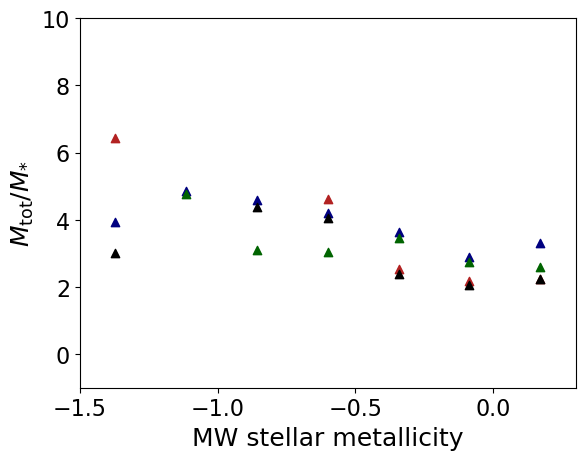

In [339]:
# plt.scatter(blue_spirals['ZH_MW_Re_fit'], blue_spirals['Mtot_Mstar'], marker='+', color='b', s=10, alpha=0.3)
# plt.scatter(green_spirals['ZH_MW_Re_fit'], green_spirals['Mtot_Mstar'], marker='x', color='g', s=10, alpha=0.3)
# plt.scatter(red_spirals['ZH_MW_Re_fit'], red_spirals['Mtot_Mstar'], marker='o', edgecolor='r', facecolor='none',s=8, alpha=0.3)
# plt.scatter(ellipticals['ZH_MW_Re_fit'], ellipticals['Mtot_Mstar'], marker='o', edgecolor='k', facecolor='none',s=8, alpha=0.3)


# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, b_med, yerr=np.abs(np.transpose(b_pct) - b_med), linestyle='none', marker='^', color='navy')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, g_med, yerr=np.abs(np.transpose(g_pct) - g_med), linestyle='none', marker='^', color='darkgreen')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, r_med, yerr=np.abs(np.transpose(r_pct) - r_med), linestyle='none', marker='^', color='firebrick')

plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, b_med,  marker='^', color='navy')
plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, g_med,  marker='^', color='darkgreen')
plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, r_med,  marker='^', color='firebrick')
plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, e_med,  marker='^', color='k')


plt.ylim(-1,10)
plt.xlim(-1.5,0.3)
plt.ylabel(r'$M_{\rm tot}/M_{*}$')
plt.xlabel(r'MW stellar metallicity')
plt.savefig(plot_dir + 'MWZ_MtotMstar_manga_scatter_median.png', bbox_inches='tight')

In [340]:
MW_Z_bins = np.linspace(-1.5,0.3,8)
b_ind = np.digitize(HI_blue['ZH_MW_Re_fit'], MW_Z_bins, right=True)
g_ind = np.digitize(HI_green['ZH_MW_Re_fit'], MW_Z_bins, right=True)
r_ind = np.digitize(HI_red['ZH_MW_Re_fit'], MW_Z_bins, right=True)
e_ind = np.digitize(ellipticals['ZH_MW_Re_fit'], MW_Z_bins, right=True)

In [341]:
b_med = []
b_scat = []

g_med = []
g_scat = []

r_med = []
r_scat = []

e_med = []
e_scat = []

for i in range(1,8):

    b_med.append(np.median(HI_blue[b_ind == i]['Mtot_Mvis']))
    b_scat.append(np.std(HI_blue[b_ind == i]['Mtot_Mvis']))
    # b_pct.append(np.percentile(HI_metallicity_blue[b_ind == i]['Mtot_Mvis'], [16,84]))

    g_med.append(np.median(HI_green[g_ind == i]['Mtot_Mvis']))
    g_scat.append(np.std(HI_green[g_ind == i]['Mtot_Mvis']))
    # g_pct.append(np.percentile(HI_metallicity_green[g_ind == i]['Mtot_Mvis'], [16,84]))

    r_med.append(np.median(HI_red[r_ind == i]['Mtot_Mvis']))
    r_scat.append(np.std(HI_red[r_ind == i]['Mtot_Mvis']))
    # r_pct.append(np.percentile(HI_metallicity_red[r_ind == i]['Mtot_Mvis'], [16,84]))

    e_med.append(np.median(ellipticals[e_ind == i]['Mtot_Mvis']))
    e_scat.append(np.std(ellipticals[e_ind == i]['Mtot_Mvis']))

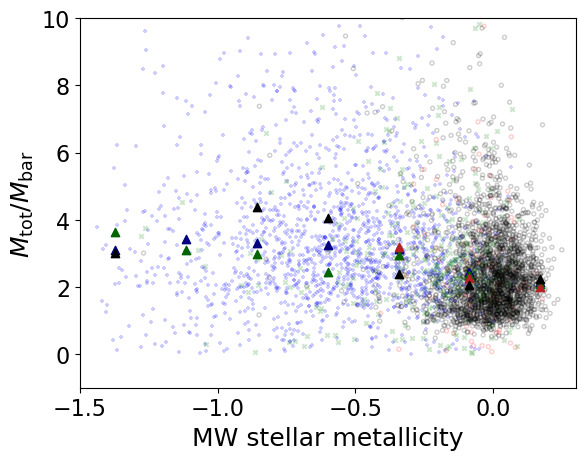

In [342]:
plt.scatter(HI_blue['ZH_MW_Re_fit'], HI_blue['Mtot_Mvis'], marker='+', color='b', s=10, alpha=0.2)
plt.scatter(HI_green['ZH_MW_Re_fit'], HI_green['Mtot_Mvis'], marker='x', color='g', s=10, alpha=0.2)
plt.scatter(HI_red['ZH_MW_Re_fit'], HI_red['Mtot_Mvis'], marker='o', edgecolor='r', facecolor='none',s=8, alpha=0.2)
plt.scatter(ellipticals['ZH_MW_Re_fit'], ellipticals['Mtot_Mvis'], marker='o', edgecolor='k', facecolor='none',s=8, alpha=0.2)


# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, b_med, yerr=np.abs(np.transpose(b_pct) - b_med), linestyle='none', marker='^', color='navy')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, g_med, yerr=np.abs(np.transpose(g_pct) - g_med), linestyle='none', marker='^', color='darkgreen')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, r_med, yerr=np.abs(np.transpose(r_pct) - r_med), linestyle='none', marker='^', color='firebrick')

plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, b_med,  marker='^', color='navy')
plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, g_med,  marker='^', color='darkgreen')
plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, r_med,  marker='^', color='firebrick')
plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, e_med,  marker='^', color='k')


plt.ylim(-1,10)
plt.xlim(-1.5,0.3)
plt.ylabel(r'$M_{\rm tot}/M_{\rm bar}$')
plt.xlabel(r'MW stellar metallicity')
plt.savefig(plot_dir + 'MWZ_MtotMvis_manga_scatter.png', bbox_inches='tight')

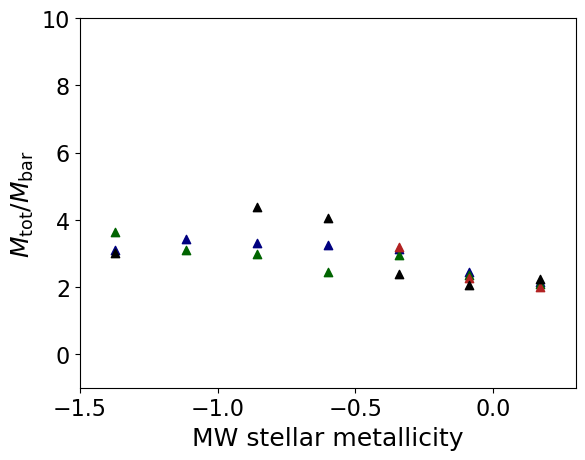

In [343]:
# plt.scatter(HI_blue['ZH_MW_Re_fit'], HI_blue['Mtot_Mvis'], marker='+', color='b', s=10, alpha=0.3)
# plt.scatter(HI_green['ZH_MW_Re_fit'], HI_green['Mtot_Mvis'], marker='x', color='g', s=10, alpha=0.3)
# plt.scatter(HI_red['ZH_MW_Re_fit'], HI_red['Mtot_Mvis'], marker='o', edgecolor='r', facecolor='none',s=8, alpha=0.3)
# plt.scatter(ellipticals['ZH_MW_Re_fit'], ellipticals['Mtot_Mvis'], marker='o', edgecolor='k', facecolor='none',s=8, alpha=0.3)


# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, b_med, yerr=np.abs(np.transpose(b_pct) - b_med), linestyle='none', marker='^', color='navy')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, g_med, yerr=np.abs(np.transpose(g_pct) - g_med), linestyle='none', marker='^', color='darkgreen')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, r_med, yerr=np.abs(np.transpose(r_pct) - r_med), linestyle='none', marker='^', color='firebrick')

plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, b_med,  marker='^', color='navy')
plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, g_med,  marker='^', color='darkgreen')
plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, r_med,  marker='^', color='firebrick')
plt.scatter((MW_Z_bins[1:] + MW_Z_bins[:-1])/2, e_med,  marker='^', color='k')


plt.ylim(-1,10)
plt.xlim(-1.5,0.3)
plt.ylabel(r'$M_{\rm tot}/M_{\rm bar}$')
plt.xlabel(r'MW stellar metallicity')
plt.savefig(plot_dir + 'MWZ_MtotMvis_manga_scatter_median.png', bbox_inches='tight')

### stellar age

In [357]:
MW_age_bins = np.linspace(9,10,8)
b_ind = np.digitize(blue_spirals['Age_MW_Re_fit'], MW_age_bins, right=True)
g_ind = np.digitize(green_spirals['Age_MW_Re_fit'], MW_age_bins, right=True)
r_ind = np.digitize(red_spirals['Age_MW_Re_fit'], MW_age_bins, right=True)
e_ind = np.digitize(ellipticals['Age_MW_Re_fit'], MW_age_bins, right=True)

In [358]:
b_med = []
b_scat = []

g_med = []
g_scat = []

r_med = []
r_scat = []

e_med = []
e_scat = []

for i in range(1,8):

    b_med.append(np.median(blue_spirals[b_ind == i]['Mtot_Mstar']))
    b_scat.append(np.std(blue_spirals[b_ind == i]['Mtot_Mstar']))
    # b_pct.append(np.percentile(HI_metallicity_blue[b_ind == i]['Mtot_Mvis'], [16,84]))

    g_med.append(np.median(green_spirals[g_ind == i]['Mtot_Mstar']))
    g_scat.append(np.std(green_spirals[g_ind == i]['Mtot_Mstar']))
    # g_pct.append(np.percentile(HI_metallicity_green[g_ind == i]['Mtot_Mvis'], [16,84]))

    r_med.append(np.median(red_spirals[r_ind == i]['Mtot_Mstar']))
    r_scat.append(np.std(red_spirals[r_ind == i]['Mtot_Mstar']))
    # r_pct.append(np.percentile(HI_metallicity_red[r_ind == i]['Mtot_Mvis'], [16,84]))

    e_med.append(np.median(ellipticals[e_ind == i]['Mtot_Mstar']))
    e_scat.append(np.std(ellipticals[e_ind == i]['Mtot_Mstar']))

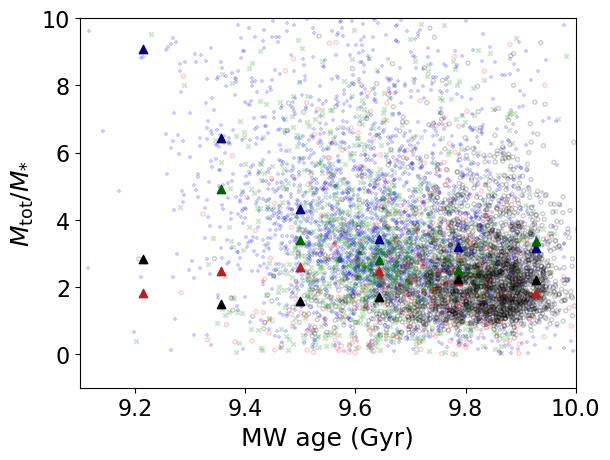

In [361]:
plt.scatter(blue_spirals['Age_MW_Re_fit'], blue_spirals['Mtot_Mstar'], marker='+', color='b', s=10, alpha=0.2)
plt.scatter(green_spirals['Age_MW_Re_fit'], green_spirals['Mtot_Mstar'], marker='x', color='g', s=10, alpha=0.2)
plt.scatter(red_spirals['Age_MW_Re_fit'], red_spirals['Mtot_Mstar'], marker='o', edgecolor='r', facecolor='none',s=8, alpha=0.2)
plt.scatter(ellipticals['Age_MW_Re_fit'], ellipticals['Mtot_Mstar'], marker='o', edgecolor='k', facecolor='none',s=8, alpha=0.2)


# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, b_med, yerr=np.abs(np.transpose(b_pct) - b_med), linestyle='none', marker='^', color='navy')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, g_med, yerr=np.abs(np.transpose(g_pct) - g_med), linestyle='none', marker='^', color='darkgreen')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, r_med, yerr=np.abs(np.transpose(r_pct) - r_med), linestyle='none', marker='^', color='firebrick')

plt.scatter((MW_age_bins[1:] + MW_age_bins[:-1])/2, b_med,  marker='^', color='navy')
plt.scatter((MW_age_bins[1:] + MW_age_bins[:-1])/2, g_med,  marker='^', color='darkgreen')
plt.scatter((MW_age_bins[1:] + MW_age_bins[:-1])/2, r_med,  marker='^', color='firebrick')
plt.scatter((MW_age_bins[1:] + MW_age_bins[:-1])/2, e_med,  marker='^', color='k')


plt.ylim(-1,10)
plt.xlim(9.1,10)
plt.ylabel(r'$M_{\rm tot}/M_{*}$')
plt.xlabel(r'MW age (Gyr)')
plt.savefig(plot_dir + 'MWage_MtotMstar_manga_scatter.png', bbox_inches='tight')

In [362]:
b_ind = np.digitize(HI_blue['Age_MW_Re_fit'], MW_age_bins, right=True)
g_ind = np.digitize(HI_green['Age_MW_Re_fit'], MW_age_bins, right=True)
r_ind = np.digitize(HI_red['Age_MW_Re_fit'], MW_age_bins, right=True)
e_ind = np.digitize(ellipticals['Age_MW_Re_fit'], MW_age_bins, right=True)

In [363]:
b_med = []
b_scat = []

g_med = []
g_scat = []

r_med = []
r_scat = []

e_med = []
e_scat = []

for i in range(1,8):

    b_med.append(np.median(HI_blue[b_ind == i]['Mtot_Mvis']))
    b_scat.append(np.std(HI_blue[b_ind == i]['Mtot_Mvis']))
    # b_pct.append(np.percentile(HI_metallicity_blue[b_ind == i]['Mtot_Mvis'], [16,84]))

    g_med.append(np.median(HI_green[g_ind == i]['Mtot_Mvis']))
    g_scat.append(np.std(HI_green[g_ind == i]['Mtot_Mvis']))
    # g_pct.append(np.percentile(HI_metallicity_green[g_ind == i]['Mtot_Mvis'], [16,84]))

    r_med.append(np.median(HI_red[r_ind == i]['Mtot_Mvis']))
    r_scat.append(np.std(HI_red[r_ind == i]['Mtot_Mvis']))
    # r_pct.append(np.percentile(HI_metallicity_red[r_ind == i]['Mtot_Mvis'], [16,84]))

    e_med.append(np.median(ellipticals[e_ind == i]['Mtot_Mvis']))
    e_scat.append(np.std(ellipticals[e_ind == i]['Mtot_Mvis']))

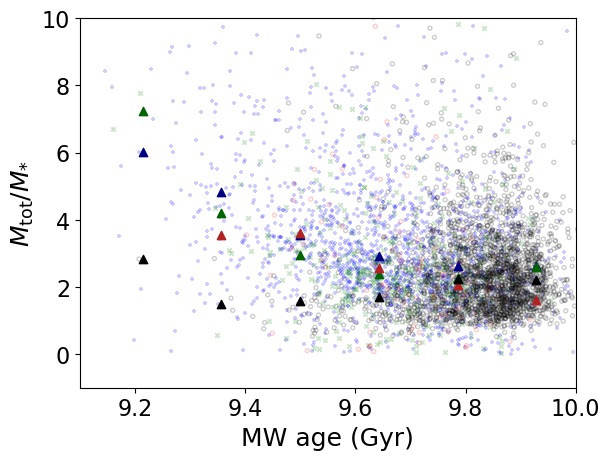

In [364]:
plt.scatter(HI_blue['Age_MW_Re_fit'], HI_blue['Mtot_Mvis'], marker='+', color='b', s=10, alpha=0.2)
plt.scatter(HI_green['Age_MW_Re_fit'], HI_green['Mtot_Mvis'], marker='x', color='g', s=10, alpha=0.2)
plt.scatter(HI_red['Age_MW_Re_fit'], HI_red['Mtot_Mvis'], marker='o', edgecolor='r', facecolor='none',s=8, alpha=0.2)
plt.scatter(ellipticals['Age_MW_Re_fit'], ellipticals['Mtot_Mvis'], marker='o', edgecolor='k', facecolor='none',s=8, alpha=0.2)


# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, b_med, yerr=np.abs(np.transpose(b_pct) - b_med), linestyle='none', marker='^', color='navy')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, g_med, yerr=np.abs(np.transpose(g_pct) - g_med), linestyle='none', marker='^', color='darkgreen')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, r_med, yerr=np.abs(np.transpose(r_pct) - r_med), linestyle='none', marker='^', color='firebrick')

plt.scatter((MW_age_bins[1:] + MW_age_bins[:-1])/2, b_med,  marker='^', color='navy')
plt.scatter((MW_age_bins[1:] + MW_age_bins[:-1])/2, g_med,  marker='^', color='darkgreen')
plt.scatter((MW_age_bins[1:] + MW_age_bins[:-1])/2, r_med,  marker='^', color='firebrick')
plt.scatter((MW_age_bins[1:] + MW_age_bins[:-1])/2, e_med,  marker='^', color='k')


plt.ylim(-1,10)
plt.xlim(9.1,10)
plt.ylabel(r'$M_{\rm tot}/M_{*}$')
plt.xlabel(r'MW age (Gyr)')
plt.savefig(plot_dir + 'MWage_MtotMvis_manga_scatter.png', bbox_inches='tight')

In [404]:
MW_age_bins = np.linspace(9,10,8)
b_ind = np.digitize(blue_spirals['Age_MW_Re_fit'], MW_age_bins, right=True)
g_ind = np.digitize(green_spirals['Age_MW_Re_fit'], MW_age_bins, right=True)
r_ind = np.digitize(red_spirals['Age_MW_Re_fit'], MW_age_bins, right=True)
e_ind = np.digitize(ellipticals['Age_MW_Re_fit'], MW_age_bins, right=True)

In [405]:
b_med = []
b_scat = []

g_med = []
g_scat = []

r_med = []
r_scat = []

e_med = []
e_scat = []

for i in range(1,8):

    b_med.append(np.median(blue_spirals[b_ind == i]['R90_kpc']))
    # b_scat.append(np.std(blue_spirals[b_ind == i]['Mtot_Mstar']))
    # b_pct.append(np.percentile(HI_metallicity_blue[b_ind == i]['Mtot_Mvis'], [16,84]))

    g_med.append(np.median(green_spirals[g_ind == i]['R90_kpc']))
    # g_scat.append(np.std(green_spirals[g_ind == i]['Mtot_Mstar']))
    # g_pct.append(np.percentile(HI_metallicity_green[g_ind == i]['Mtot_Mvis'], [16,84]))

    r_med.append(np.median(red_spirals[r_ind == i]['R90_kpc']))
    # r_scat.append(np.std(red_spirals[r_ind == i]['Mtot_Mstar']))
    # r_pct.append(np.percentile(HI_metallicity_red[r_ind == i]['Mtot_Mvis'], [16,84]))

    e_med.append(np.median(ellipticals[e_ind == i]['R90_kpc']))
    # e_scat.append(np.std(ellipticals[e_ind == i]['Mtot_Mstar']))

/Users/nityaravi/miniforge3/envs/RotationCurves/lib/python3.12/site-packages/numpy/core/fromnumeric.py:3502: RuntimeWarning: Mean of empty slice.
  return mean(axis=axis, dtype=dtype, out=out, **kwargs)
/Users/nityaravi/miniforge3/envs/RotationCurves/lib/python3.12/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Text(0.5, 0, 'MW age (Gyr)')

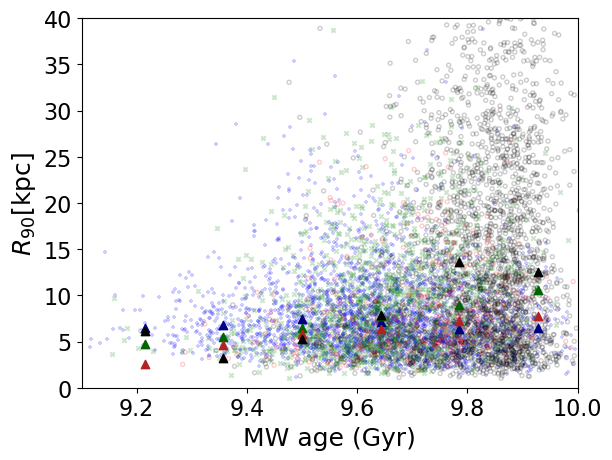

In [406]:
plt.scatter(blue_spirals['Age_MW_Re_fit'], blue_spirals['R90_kpc'], marker='+', color='b', s=10, alpha=0.2)
plt.scatter(green_spirals['Age_MW_Re_fit'], green_spirals['R90_kpc'], marker='x', color='g', s=10, alpha=0.2)
plt.scatter(red_spirals['Age_MW_Re_fit'], red_spirals['R90_kpc'], marker='o', edgecolor='r', facecolor='none',s=8, alpha=0.2)
plt.scatter(ellipticals['Age_MW_Re_fit'], ellipticals['R90_kpc'], marker='o', edgecolor='k', facecolor='none',s=8, alpha=0.2)


# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, b_med, yerr=np.abs(np.transpose(b_pct) - b_med), linestyle='none', marker='^', color='navy')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, g_med, yerr=np.abs(np.transpose(g_pct) - g_med), linestyle='none', marker='^', color='darkgreen')
# plt.errorbar((z_bins[1:] + z_bins[:-1])/2, r_med, yerr=np.abs(np.transpose(r_pct) - r_med), linestyle='none', marker='^', color='firebrick')

plt.scatter((MW_age_bins[1:] + MW_age_bins[:-1])/2, b_med,  marker='^', color='navy')
plt.scatter((MW_age_bins[1:] + MW_age_bins[:-1])/2, g_med,  marker='^', color='darkgreen')
plt.scatter((MW_age_bins[1:] + MW_age_bins[:-1])/2, r_med,  marker='^', color='firebrick')
plt.scatter((MW_age_bins[1:] + MW_age_bins[:-1])/2, e_med,  marker='^', color='k')


plt.ylim(0,40)
plt.xlim(9.1,10)
plt.ylabel(r'$R_{90}$[kpc]')
plt.xlabel(r'MW age (Gyr)')
# plt.savefig(plot_dir + 'MWage_MtotMstar_manga_scatter.png', bbox_inches='tight')

Text(0, 0.5, 'MW age (Gyr)')

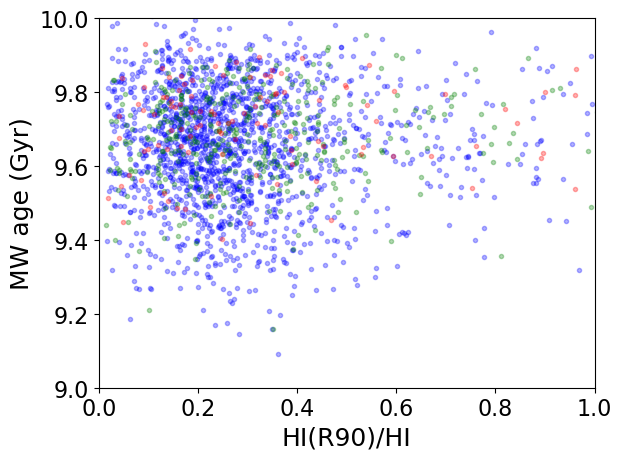

In [414]:
plt.scatter(10**(HI_blue['logHI_R90'] - HI_blue['logHI']), HI_blue['Age_MW_Re_fit'], marker='.', color='b', alpha=0.3)
plt.scatter(10**(HI_green['logHI_R90'] - HI_green['logHI']), HI_green['Age_MW_Re_fit'], marker='.', color='g', alpha=0.3)
plt.scatter(10**(HI_red['logHI_R90'] - HI_red['logHI']), HI_red['Age_MW_Re_fit'], marker='.', color='r', alpha=0.3)

plt.xlim(0, 1)
plt.ylim(9,10)
plt.xlabel('HI(R90)/HI')
plt.ylabel('MW age (Gyr)')

Text(0, 0.5, 'Mtot/Mvis')

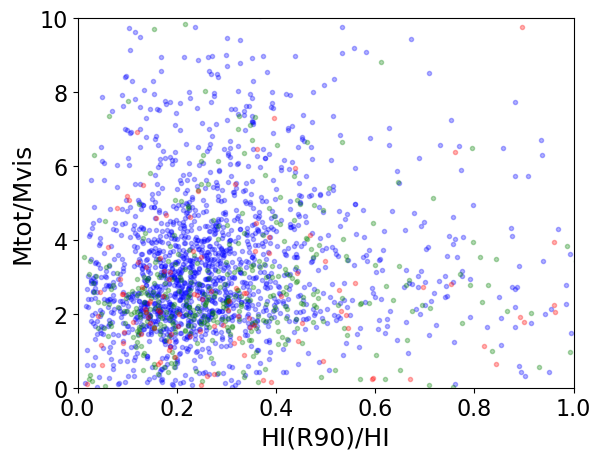

In [415]:
plt.scatter(10**(HI_blue['logHI_R90'] - HI_blue['logHI']), HI_blue['Mtot_Mvis'], marker='.', color='b', alpha=0.3)
plt.scatter(10**(HI_green['logHI_R90'] - HI_green['logHI']), HI_green['Mtot_Mvis'], marker='.', color='g', alpha=0.3)
plt.scatter(10**(HI_red['logHI_R90'] - HI_red['logHI']), HI_red['Mtot_Mvis'], marker='.', color='r', alpha=0.3)

plt.xlim(0, 1)
plt.ylim(0,10)
plt.xlabel('HI(R90)/HI')
plt.ylabel('Mtot/Mvis')

## Grid Plots

(array([ 783., 1412.,  589.,  257.,  107.,   61.,   44.,   24.,   14.]),
 array([ 0.        ,  1.55555556,  3.11111111,  4.66666667,  6.22222222,
         7.77777778,  9.33333333, 10.88888889, 12.44444444, 14.        ]),
 <BarContainer object of 9 artists>)

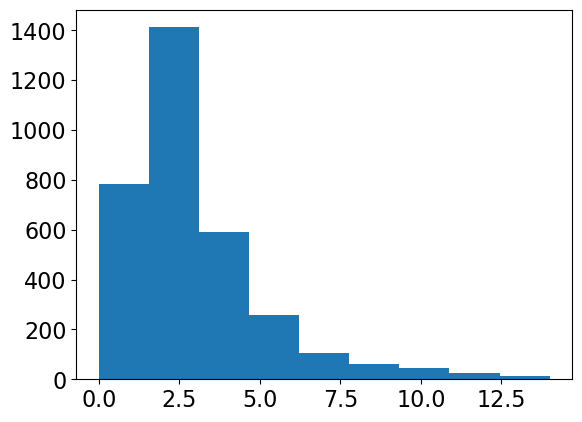

In [365]:
plt.hist(10**(good_gals['M_R90']-good_gals['M90_disk']), bins=np.linspace(0,14,10))

In [366]:
mr_bins = np.linspace(-17, -22.5, 6)
z_bins = np.linspace(8, 9.4, 6)

In [367]:
## bin the data
mr_indices = np.digitize(good_gals['rabsmag'], mr_bins, right=True)
z_indices = np.digitize(good_gals['Z'], z_bins, right=True)

In [368]:
mr_indices

array([3, 3, 3, ..., 2, 1, 4])

In [369]:
mtot_mstar = np.zeros((5,5))
for i in range(1,6):
    for j in range(1,6):

        mask = np.logical_and(mr_indices == i, z_indices==j)

        gals = good_gals[mask]
        med = ma.median(10**(gals['M_R90']-(gals['M90_disk']+np.log10(0.73))))
        mtot_mstar[i-1][j-1] = med

/Users/nityaravi/miniforge3/envs/RotationCurves/lib/python3.12/site-packages/numpy/ma/core.py:5334: RuntimeWarning: Mean of empty slice.
  result = super().mean(axis=axis, dtype=dtype, **kwargs)[()]
/Users/nityaravi/miniforge3/envs/RotationCurves/lib/python3.12/site-packages/numpy/core/_methods.py:121: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(


In [370]:
mtot_mstar

array([[5.51180594, 5.59914325, 3.32046736, 0.46196488,        nan],
       [3.72569141, 4.57405999, 3.61997733, 2.47464704, 0.04867263],
       [2.69712755, 3.5480214 , 2.95528451, 2.05756948, 2.12919169],
       [1.92369663, 2.84365061, 2.66010484, 2.35051922, 2.26406435],
       [3.1943634 , 3.27828435, 3.33884988, 2.94615374, 3.34113009]])

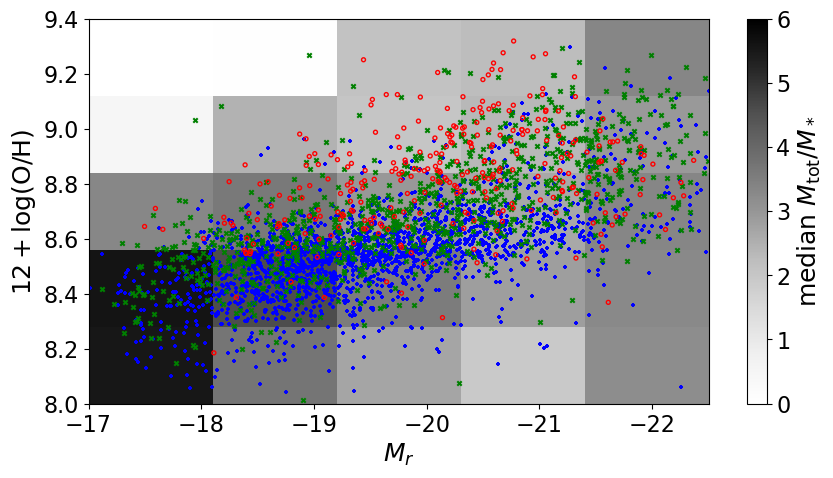

In [120]:
fig, ax = plt.subplots(figsize=(10,5))
im =ax.pcolormesh(mr_bins, z_bins, np.transpose(mtot_mstar), vmin=0, vmax=6, cmap='Greys')
cb = plt.colorbar(im, ax=ax)
cb.set_label(label=r'median $M_{\rm tot}/M_*$', size=18)
im.figure.axes[1].tick_params(axis="y", labelsize=16)
ax.scatter(blue['rabsmag'], blue['Z'], marker='+', color='b', s=10)
ax.scatter(green['rabsmag'], green['Z'], marker='x', color='g', s=10)
ax.scatter(red['rabsmag'], red['Z'], marker='o', edgecolor='r', facecolor='none',s=8)
ax.tick_params(labelsize=16, axis='both')
ax.set_xlim(-17,-22.5)
ax.set_ylim(8,9.4)
ax.set_xlabel(r'$M_r$', fontsize=18)
ax.set_ylabel(r'$12 + \log(\rm O/H)$', fontsize=18)
plt.savefig(plot_dir + 'Mr_12logOH_MtotMstar_grid.png', bbox_inches='tight')

Text(0, 0.5, '$M_{\\rm tot}/M_*$')

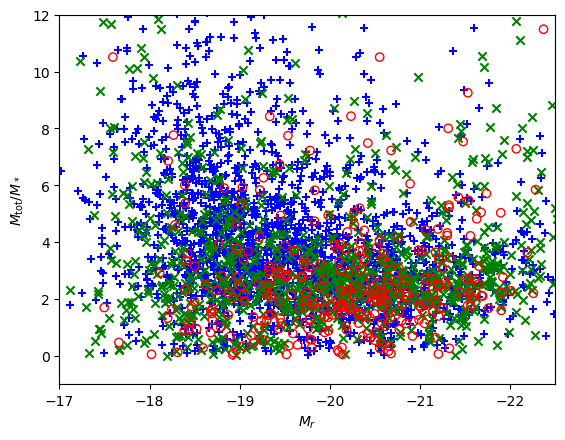

In [130]:
plt.scatter(blue['rabsmag'],10**(blue['M_R90']-(blue['M90_disk']+np.log10(0.73))), marker='+', color='b',)
plt.scatter(green['rabsmag'],10**(green['M_R90']-(green['M90_disk']+np.log10(0.73))), marker='x', color='g',)
plt.scatter(red['rabsmag'],10**(red['M_R90']-(red['M90_disk']+np.log10(0.73))), marker='o', edgecolor='r', facecolor='none',)
plt.ylim(-1,12)
plt.xlim(-17, -22.5)

plt.xlabel(r'$M_r$')
plt.ylabel(r'$M_{\rm tot}/M_*$')

Text(0, 0.5, '$M_{\\rm tot}/M_*$')

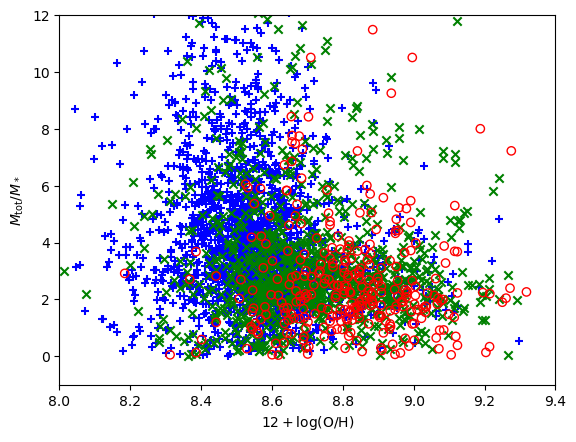

In [133]:
plt.scatter(blue['Z'],10**(blue['M_R90']-(blue['M90_disk']+np.log10(0.73))), marker='+', color='b',)
plt.scatter(green['Z'],10**(green['M_R90']-(green['M90_disk']+np.log10(0.73))), marker='x', color='g',)
plt.scatter(red['Z'],10**(red['M_R90']-(red['M90_disk']+np.log10(0.73))), marker='o', edgecolor='r', facecolor='none',)
plt.ylim(-1,12)
plt.xlim(8, 9.4)

plt.xlabel(r'$12 + \log(\rm O/H)$')
plt.ylabel(r'$M_{\rm tot}/M_*$')

In [18]:
HI_spirals = good_gals[good_gals['logHI_R90'] > 0]

In [19]:
HI_spirals['param_H2'] = np.zeros(len(HI_spirals))
HI_spirals['param_H2_h'] = np.zeros(len(HI_spirals))
HI_spirals['param_He_h'] = np.zeros(len(HI_spirals))
HI_spirals['param_He90_h'] = np.zeros(len(HI_spirals))
HI_spirals['Mbar'] = np.zeros(len(HI_spirals))


for i in range(len(HI_spirals)):
    
    if HI_spirals['CMD_class'][i] == 1:
        HI_spirals['param_H2'][i] = -0.4*HI_spirals['rabsmag'][i] +1.12
    elif HI_spirals['CMD_class'][i] == 2 or HI_spirals['CMD_class'][i] == 3:
        HI_spirals['param_H2'][i] = -0.27*HI_spirals['rabsmag'][i] + 3.62

    HI_spirals['param_H2_h'][i] = HI_spirals['param_H2'][i] + np.log10(0.7)
    HI_spirals['param_He_h'][i] = np.log10(0.7) -np.log10(3) + np.log10(10**HI_spirals['logHI'][i] + 10**HI_spirals['param_H2'][i])
    HI_spirals['param_He90_h'][i] = np.log10(0.7) -np.log10(3) + np.log10(10**HI_spirals['logHI_R90'][i] + 10**HI_spirals['param_H2'][i])



for i in range(len(HI_spirals)):
    HI_spirals['Mbar'][i] = np.log10(10**(HI_spirals['M90_disk'][i] + np.log10(0.73)) + 10**(HI_spirals['logHI_R90'][i]+np.log10(0.7)) + 10**HI_spirals['param_H2_h'][i] + 10**HI_spirals['param_He90_h'][i])

In [20]:
mr_indices = np.digitize(HI_spirals['rabsmag'], mr_bins, right=True)
z_indices = np.digitize(HI_spirals['Z'], z_bins, right=True)

In [21]:
mtot_mvis = np.zeros((5,5))
for i in range(1,):
    for j in range(1,6):

        mask = np.logical_and(mr_indices == i, z_indices==j)

        gals = HI_spirals[mask]
        med = ma.median(10**(gals['M_R90']-gals['Mbar']))
        mtot_mvis[i-1][j-1] = med

In [22]:
HI_blue = HI_spirals[HI_spirals['CMD_class'] == 1]
HI_green = HI_spirals[HI_spirals['CMD_class'] == 2]
HI_red = HI_spirals[HI_spirals['CMD_class'] == 3]

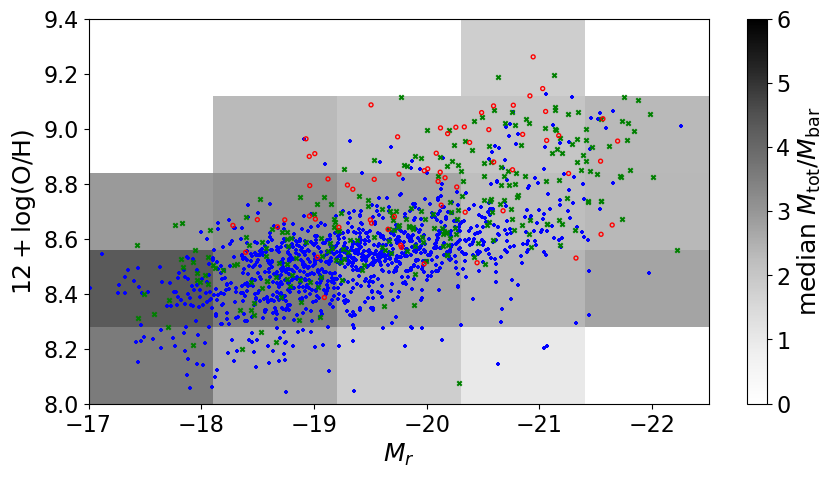

In [23]:
fig, ax = plt.subplots(figsize=(10,5))
im =ax.pcolormesh(mr_bins, z_bins, np.transpose(mtot_mvis), vmin=0, vmax=6, cmap='Greys')
cb = plt.colorbar(im, ax=ax)
cb.set_label(label=r'median $M_{\rm tot}/M_{\rm bar}$', size=18)
im.figure.axes[1].tick_params(axis="y", labelsize=16)
ax.scatter(HI_blue['rabsmag'], HI_blue['Z'], marker='+', color='b', s=10)
ax.scatter(HI_green['rabsmag'], HI_green['Z'], marker='x', color='g', s=10)
ax.scatter(HI_red['rabsmag'], HI_red['Z'], marker='o', edgecolor='r', facecolor='none',s=8)
ax.tick_params(labelsize=16, axis='both')
ax.set_xlim(-17,-22.5)
ax.set_ylim(8,9.4)
ax.set_xlabel(r'$M_r$', fontsize=18)
ax.set_ylabel(r'$12 + \log(\rm O/H)$', fontsize=18)
plt.savefig(plot_dir + 'Mr_12logOH_MtotMbar_grid.png', bbox_inches='tight')

## same thing with stellar metallicity

### make spiral + elliptical sample

(array([  1.,   0.,   0.,   5., 882., 772., 478., 483., 522., 560., 608.,
        714., 824., 923., 954., 931., 729., 411., 192.,  44.,   6.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.]),
 array([-0.7       , -0.65641026, -0.61282051, -0.56923077, -0.52564103,
        -0.48205128, -0.43846154, -0.39487179, -0.35128205, -0.30769231,
        -0.26410256, -0.22051282, -0.17692308, -0.13333333, -0.08974359,
        -0.04615385, -0.0025641 ,  0.04102564,  0.08461538,  0.12820513,
         0.17179487,  0.21538462,  0.25897436,  0.3025641 ,  0.34615385,
         0.38974359,  0.43333333,  0.47692308,  0.52051282,  0.56410256,
         0.60769231,  0.65128205,  0.69487179,  0.73846154,  0.78205128,
         0.82564103,  0.86923077,  0.91282051,  0.95641026,  1.        ]),
 <BarContainer object of 39 artists>)

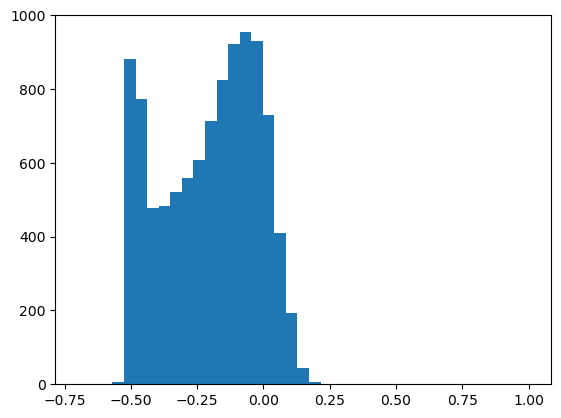

In [50]:
plt.hist(master_table['ZH_LW_Re_fit'], bins=np.linspace(-0.7,1,40))

In [51]:
alpha_mask = master_table['alpha'] <= 99
vel_mask = np.logical_and(master_table['V_R90'] < 1000, master_table['V_R90'] > 10)
vel_err_mask = master_table['v_max_err']/master_table['v_max'] <= 2

In [52]:
spirals = master_table[np.logical_and(alpha_mask, np.logical_and(vel_mask, vel_err_mask))]

In [53]:
ellipticals = master_table[master_table['Mvir'] > 0]

In [54]:
spirals_blue = spirals[spirals['CMD_class'] == 1]
spirals_green = spirals[spirals['CMD_class'] == 2]
spirals_red = spirals[spirals['CMD_class'] == 3]

In [59]:
mr_bins = np.linspace(-17, -23, 7)
z_bins = np.linspace(-0.5, 0.2, 8)

In [60]:
s_mr_indices = np.digitize(spirals['rabsmag'], mr_bins, right=True)
s_z_indices = np.digitize(spirals['ZH_LW_Re_fit'], z_bins, right=True)

e_mr_indices = np.digitize(ellipticals['rabsmag'], mr_bins, right=True)
e_z_indices = np.digitize(ellipticals['ZH_LW_Re_fit'], z_bins, right=True)



In [64]:
mtot_mstar = np.zeros((6,7))
for i in range(1,7):
    for j in range(1,8):

        s_mask = np.logical_and(s_mr_indices == i, s_z_indices==j)
        e_mask = np.logical_and(e_mr_indices == i, e_z_indices==j)

        
        s_gals = spirals[s_mask]
        e_gals = ellipticals[e_mask]

        s_ratio = 10**(s_gals['M_R90']-(s_gals['M90_disk']+np.log10(0.73)))
        e_ratio = 10**(e_gals['Mvir'] - e_gals['e_M_star_R90_h'])
        
        med = ma.median(np.concatenate([s_ratio, e_ratio]))
        mtot_mstar[i-1][j-1] = med

In [70]:
mtot_mstar

array([[6.26945086, 3.8703069 , 2.99218474, 1.67452843, 1.5280681 ,
               nan,        nan],
       [4.94684681, 3.98186552, 3.05536103, 1.90875858, 1.50522946,
        1.6193184 , 1.19211494],
       [3.98351947, 3.39045917, 2.77678974, 2.43064606, 1.69062722,
        1.48456844, 1.31853252],
       [3.05200513, 3.38562486, 2.88513037, 2.45647855, 2.03140962,
        1.5910192 , 1.6070922 ],
       [3.12699396, 3.16556866, 2.98460372, 2.61978489, 2.41090474,
        2.1232918 , 2.04926364],
       [5.07690784, 5.38288173, 4.16585458, 3.73152828, 3.24143955,
        2.66896748, 2.49785684]])

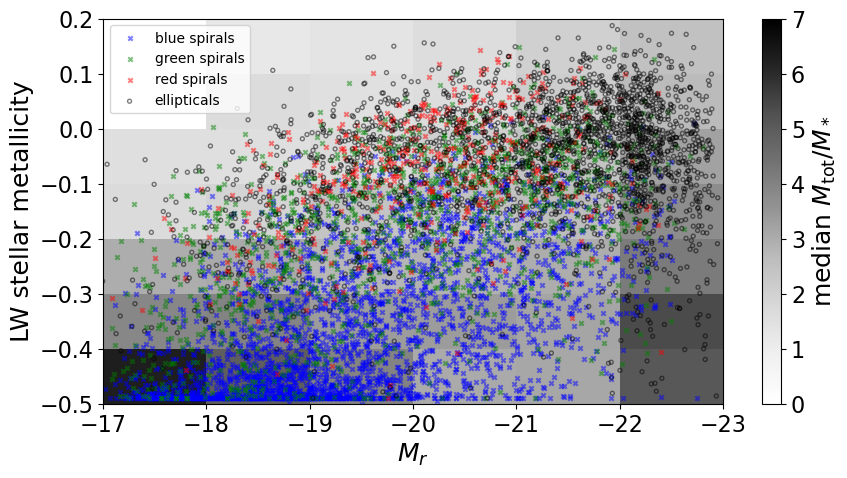

In [78]:
fig, ax = plt.subplots(figsize=(10,5))
im =ax.pcolormesh(mr_bins, z_bins, np.transpose(mtot_mstar), cmap='Greys', vmin=0, vmax=7)
cb = plt.colorbar(im, ax=ax)
cb.set_label(label=r'median $M_{\rm tot}/M_*$', size=18)
im.figure.axes[1].tick_params(axis="y", labelsize=16)
ax.scatter(spirals_blue['rabsmag'], spirals_blue['ZH_LW_Re_fit'], marker='x', color='b', s=10, label='blue spirals', alpha=0.5)
ax.scatter(spirals_green['rabsmag'], spirals_green['ZH_LW_Re_fit'], marker='x', color='g', s=10, label='green spirals', alpha=0.5)
ax.scatter(spirals_red['rabsmag'], spirals_red['ZH_LW_Re_fit'], marker='x', color='r', s=10, label='red spirals', alpha=0.5)
ax.scatter(ellipticals['rabsmag'], ellipticals['ZH_LW_Re_fit'], marker='o', edgecolor='k', facecolor='none',s=8, label='ellipticals', alpha=0.5)
ax.tick_params(labelsize=16, axis='both')
ax.set_xlim(-17,-23)
ax.set_ylim(-0.5,0.2)
ax.set_xlabel(r'$M_r$', fontsize=18)
ax.set_ylabel(r'LW stellar metallicity', fontsize=18)
plt.legend()

In [79]:
HI_spirals = spirals[spirals['logHI_R90'] > 0]

In [80]:
HI_spirals['param_H2'] = np.zeros(len(HI_spirals))
HI_spirals['param_H2_h'] = np.zeros(len(HI_spirals))
HI_spirals['param_He_h'] = np.zeros(len(HI_spirals))
HI_spirals['param_He90_h'] = np.zeros(len(HI_spirals))
HI_spirals['Mbar'] = np.zeros(len(HI_spirals))


for i in range(len(HI_spirals)):
    
    if HI_spirals['CMD_class'][i] == 1:
        HI_spirals['param_H2'][i] = -0.4*HI_spirals['rabsmag'][i] +1.12
    elif HI_spirals['CMD_class'][i] == 2 or HI_spirals['CMD_class'][i] == 3:
        HI_spirals['param_H2'][i] = -0.27*HI_spirals['rabsmag'][i] + 3.62

    HI_spirals['param_H2_h'][i] = HI_spirals['param_H2'][i] + np.log10(0.7)
    HI_spirals['param_He_h'][i] = np.log10(0.7) -np.log10(3) + np.log10(10**HI_spirals['logHI'][i] + 10**HI_spirals['param_H2'][i])
    HI_spirals['param_He90_h'][i] = np.log10(0.7) -np.log10(3) + np.log10(10**HI_spirals['logHI_R90'][i] + 10**HI_spirals['param_H2'][i])



for i in range(len(HI_spirals)):
    HI_spirals['Mbar'][i] = np.log10(10**(HI_spirals['M90_disk'][i] + np.log10(0.73)) + 10**(HI_spirals['logHI_R90'][i]+np.log10(0.7)) + 10**HI_spirals['param_H2_h'][i] + 10**HI_spirals['param_He90_h'][i])

In [81]:
s_mr_indices = np.digitize(HI_spirals['rabsmag'], mr_bins, right=True)
s_z_indices = np.digitize(HI_spirals['ZH_LW_Re_fit'], z_bins, right=True)

e_mr_indices = np.digitize(ellipticals['rabsmag'], mr_bins, right=True)
e_z_indices = np.digitize(ellipticals['ZH_LW_Re_fit'], z_bins, right=True)

In [83]:
HI_spirals_blue = HI_spirals[HI_spirals['CMD_class'] == 1]
HI_spirals_green = HI_spirals[HI_spirals['CMD_class'] == 2]
HI_spirals_red = HI_spirals[HI_spirals['CMD_class'] == 3]

In [86]:
mtot_mvis = np.zeros((6,7))
for i in range(1,7):
    for j in range(1,8):

        s_mask = np.logical_and(s_mr_indices == i, s_z_indices==j)
        e_mask = np.logical_and(e_mr_indices == i, e_z_indices==j)

        
        s_gals = HI_spirals[s_mask]
        e_gals = ellipticals[e_mask]

        s_ratio = 10**(gals['M_R90']-gals['Mbar'])
        e_ratio = 10**(e_gals['Mvir'] - e_gals['e_M_star_R90_h'])
        
        med = ma.median(np.concatenate([s_ratio, e_ratio]))
        mtot_mvis[i-1][j-1] = med



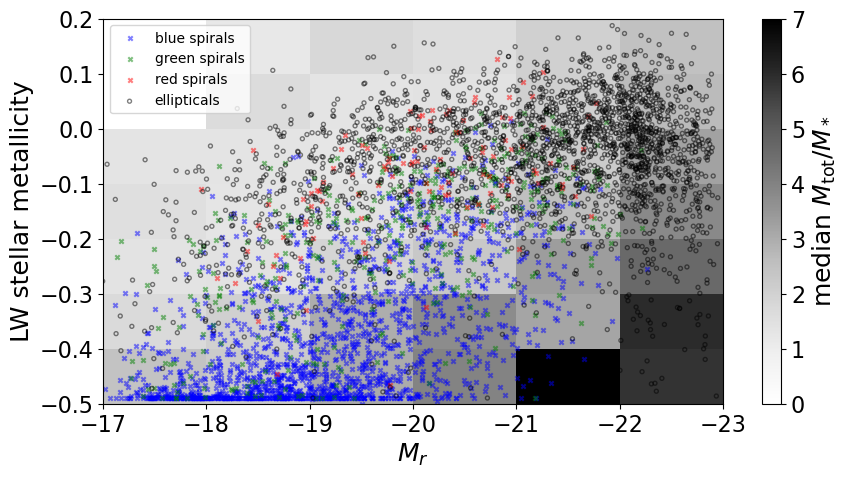

In [88]:
fig, ax = plt.subplots(figsize=(10,5))
im =ax.pcolormesh(mr_bins, z_bins, np.transpose(mtot_mvis), cmap='Greys', vmin=0, vmax=7)
cb = plt.colorbar(im, ax=ax)
cb.set_label(label=r'median $M_{\rm tot}/M_*$', size=18)
im.figure.axes[1].tick_params(axis="y", labelsize=16)
ax.scatter(HI_spirals_blue['rabsmag'], HI_spirals_blue['ZH_LW_Re_fit'], marker='x', color='b', s=10, label='blue spirals', alpha=0.5)
ax.scatter(HI_spirals_green['rabsmag'], HI_spirals_green['ZH_LW_Re_fit'], marker='x', color='g', s=10, label='green spirals', alpha=0.5)
ax.scatter(HI_spirals_red['rabsmag'], HI_spirals_red['ZH_LW_Re_fit'], marker='x', color='r', s=10, label='red spirals', alpha=0.5)
ax.scatter(ellipticals['rabsmag'], ellipticals['ZH_LW_Re_fit'], marker='o', edgecolor='k', facecolor='none',s=8, label='ellipticals', alpha=0.5)
ax.tick_params(labelsize=16, axis='both')
ax.set_xlim(-17,-23)
ax.set_ylim(-0.5,0.2)
ax.set_xlabel(r'$M_r$', fontsize=18)
ax.set_ylabel(r'LW stellar metallicity', fontsize=18)
plt.legend()

## now stellar age

(array([0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00,
        8.000e+00, 3.400e+01, 2.030e+02, 1.160e+03, 1.802e+03, 1.571e+03,
        1.456e+03, 2.878e+03, 9.260e+02]),
 array([ 0.        ,  0.25641026,  0.51282051,  0.76923077,  1.02564103,
         1.28205128,  1.53846154,  1.79487179,  2.05128205,  2.30769231,
         2.56410256,  2.82051282,  3.07692308,  3.33333333,  3.58974359,
         3.84615385,  4.1025641 ,  4.35897436,  4.61538462,  4.87179487,
         5.12820513,  5.38461538,  5.64102564,  5.8974359 ,  6.15384615,
         6.41025641,  6.66666667,  6.92307692,  7.17948718,  7.43589744,
         7.69230769,  7.94871795,  8.20512821,  8.46153846,  8.71794872,
  

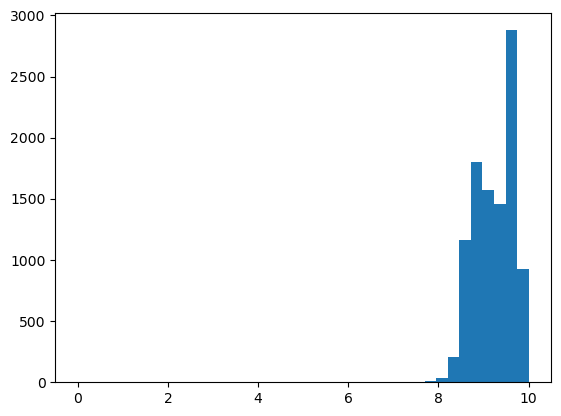

In [91]:
plt.hist(master_table['Age_LW_Re_fit'], bins=np.linspace(0,10,40))

In [102]:
mr_bins = np.linspace(-17, -23, 7)
age_bins = np.linspace(8, 10, 6)

In [103]:
s_mr_indices = np.digitize(spirals['rabsmag'], mr_bins, right=True)
s_age_indices = np.digitize(spirals['Age_LW_Re_fit'], age_bins, right=True)

e_mr_indices = np.digitize(ellipticals['rabsmag'], mr_bins, right=True)
e_age_indices = np.digitize(ellipticals['Age_LW_Re_fit'], age_bins, right=True)



In [104]:
mtot_mstar = np.zeros((6,5))
for i in range(1,7):
    for j in range(1,6):

        s_mask = np.logical_and(s_mr_indices == i, s_age_indices==j)
        e_mask = np.logical_and(e_mr_indices == i, e_age_indices==j)

        
        s_gals = spirals[s_mask]
        e_gals = ellipticals[e_mask]

        s_ratio = 10**(s_gals['M_R90']-(s_gals['M90_disk']+np.log10(0.73)))
        e_ratio = 10**(e_gals['Mvir'] - e_gals['e_M_star_R90_h'])
        
        med = ma.median(np.concatenate([s_ratio, e_ratio]))
        mtot_mstar[i-1][j-1] = med

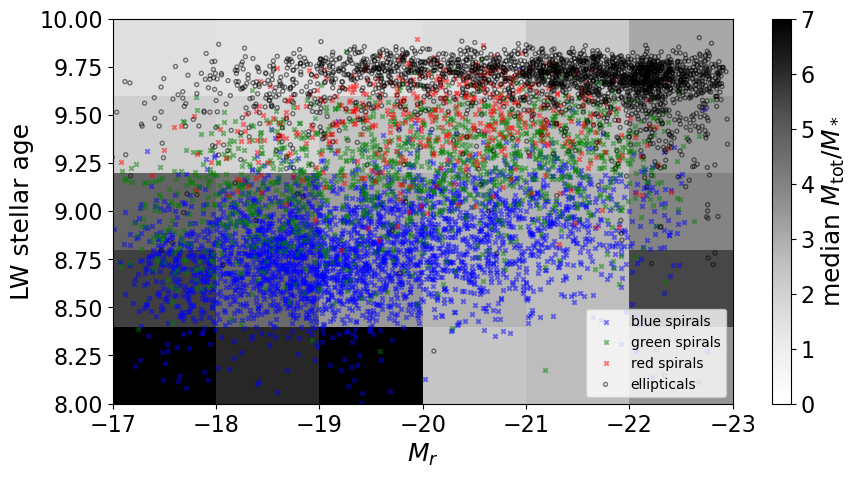

In [107]:
fig, ax = plt.subplots(figsize=(10,5))
im =ax.pcolormesh(mr_bins, age_bins, np.transpose(mtot_mstar), cmap='Greys', vmin=0, vmax=7)
cb = plt.colorbar(im, ax=ax)
cb.set_label(label=r'median $M_{\rm tot}/M_*$', size=18)
im.figure.axes[1].tick_params(axis="y", labelsize=16)
ax.scatter(spirals_blue['rabsmag'], spirals_blue['Age_LW_Re_fit'], marker='x', color='b', s=10, label='blue spirals', alpha=0.5)
ax.scatter(spirals_green['rabsmag'], spirals_green['Age_LW_Re_fit'], marker='x', color='g', s=10, label='green spirals', alpha=0.5)
ax.scatter(spirals_red['rabsmag'], spirals_red['Age_LW_Re_fit'], marker='x', color='r', s=10, label='red spirals', alpha=0.5)
ax.scatter(ellipticals['rabsmag'], ellipticals['Age_LW_Re_fit'], marker='o', edgecolor='k', facecolor='none',s=8, label='ellipticals', alpha=0.5)
ax.tick_params(labelsize=16, axis='both')
ax.set_xlim(-17,-23)
ax.set_ylim(8,10)
ax.set_xlabel(r'$M_r$', fontsize=18)
ax.set_ylabel(r'LW stellar age', fontsize=18)
plt.legend()